# Air Quality USA — Comparative Analysis Across 6 Metro Areas

*PM2.5, O3 and PM10, 2020–2026. Source: EPA AQS Data Mart (Download Daily
Data + Pre-generated Data Files), aggregated to CBSA (metropolitan area)
level.*

This notebook compares air quality across six US metropolitan areas —
New York, Houston, Denver, Chicago, Seattle, and the Los Angeles CBSA
(labeled "California" throughout this notebook and `regions.csv`, since
that CBSA is this project's only California region — not to be read as
the whole state). Each city was chosen for a distinct *primary* pollution
mechanism, listed exactly as written in `regions.csv`'s `mechanism`
column and reused verbatim in every chart title in Section 4 — several
are compound (e.g. New York's is "traffic/heating + transported wildfire
smoke"), so treat these as the dominant story per city, not as mutually
exclusive single causes. See `regions.csv` for the full mapping, and
Section 12 (conclusion 6) for where a mechanism label was revised after
seeing the data (Denver).

Data is read from `data/processed/*.parquet`, generated by
`scripts/build_dataset.py` from the raw EPA CSVs in `data/` (the raw files
are not committed to this repo, see `.gitignore`; data sources and licensing
are documented in the project README).

**Data coverage and 2026:** 2026 is a partial year, and the cut-off differs
by city (the AQI series end between 28 Feb and 1 Jun 2026; the raw
pollutant series run to 26–28 Jul 2026, see the coverage table in Section 1).
Because a partial year contains only some seasons, **2026 is excluded from
the year-over-year trend test** (Section 8) and flagged wherever it appears
in a table or chart.


## Table of Contents

1. Setup and Data Loading
2. Data Quality Check
3. Headline Comparison: AQI Across Cities
4. Per-City Detail
5. County-Level Detail Within Each CBSA
   - 5.2 Population-Weighted Exposure: Person-Days of PM2.5 Exceedance
6. Documented Events: Wind Context
7. Cross-City Correlations
8. Year-Over-Year Trend
   - 8.2 Statistical Significance (Mann-Kendall Test)
9. Weekday vs Weekend
10. Resolving Open Questions From Section 4
11. Health Economic Impact Estimate
   - 11.1 Quebec Smoke Event: Event Days Only
   - Risk Implications for Business and Investment Decisions
12. Conclusions

---
**Data source:** EPA AQS Data Mart (Download Daily Data + Pre-generated Daily AQI by CBSA)  
**Population data:** US Census Bureau, ACS 5-Year Estimates 2022  
**Period:** 2020-2026 · **Cities:** New York, Los Angeles, Houston, Denver, Chicago, Seattle  
**Pollutants:** PM2.5, O3, PM10

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create images/ directory for exported figures
Path("images").mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

DATA = Path("data/processed")
regions = pd.read_csv("regions.csv")
events = pd.read_csv("events.csv")

pollutants = pd.read_parquet(DATA / "air_quality_usa.parquet")
aqi = pd.read_parquet(DATA / "aqi_by_cbsa.parquet")
meteo = pd.read_parquet(DATA / "meteo_events.parquet")

pollutants["date"] = pd.to_datetime(pollutants["date"])
aqi["date"] = pd.to_datetime(aqi["date"])
meteo["date"] = pd.to_datetime(meteo["date"])

CITY_ORDER = regions["city"].tolist()
CITY_COLOR = dict(zip(regions["city"], regions["color"]))

print(f"Pollutants: {len(pollutants):,} rows | {pollutants['date'].min().date()} -> {pollutants['date'].max().date()}")
print(f"AQI by CBSA: {len(aqi):,} rows | {aqi['date'].min().date()} -> {aqi['date'].max().date()}")
print(f"Meteo (event months only): {len(meteo):,} rows")
print()
rows_per_city = (
    pollutants.groupby("city")
    .size()
    .reset_index(name="rows")
    .sort_values("rows", ascending=False)
    .set_index("city")
)
display(rows_per_city.style
    .format("{:,}")
    .set_caption("Rows per city (pollutants)")
    .set_table_styles([{"selector": "caption", 
                        "props": [("font-weight", "bold"), 
                                  ("font-size", "13px")]}])
)

Pollutants: 515,685 rows | 2020-01-01 -> 2026-07-28
AQI by CBSA: 13,816 rows | 2020-01-01 -> 2026-06-01
Meteo (event months only): 6,422 rows



,rows
city,
New York,"117,444"
Chicago,"113,689"
California,"87,262"
Houston,"81,303"
Denver,"61,905"
Seattle,"54,082"


In [2]:
# Data coverage by city: the AQI series and the raw pollutant series end on
# different dates, so 2026 is a partial year with a different cut-off per city.
coverage_dates = pd.DataFrame({
    "AQI first day": aqi.groupby("city")["date"].min(),
    "AQI last day": aqi.groupby("city")["date"].max(),
    "Pollutants last day": pollutants.groupby("city")["date"].max(),
}).reindex(CITY_ORDER)
for _col in coverage_dates.columns:
    coverage_dates[_col] = coverage_dates[_col].dt.strftime("%Y-%m-%d")
coverage_dates.index.name = "City"
display(coverage_dates.style
    .set_caption("Data coverage by city (2026 is a partial year; the cut-off differs by city)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-weight", "bold"), ("font-size", "13px")]}])
)


,AQI first day,AQI last day,Pollutants last day
City,,,
New York,2020-01-01,2026-06-01,2026-07-26
California,2020-01-01,2026-04-30,2026-07-28
Houston,2020-01-01,2026-04-01,2026-07-28
Denver,2020-01-01,2026-05-02,2026-07-28
Chicago,2020-01-01,2026-05-01,2026-07-28
Seattle,2020-01-01,2026-02-28,2026-07-28


## 2. Data Quality Check

Before any analysis: confirm every city has data for every pollutant, and
flag any gaps instead of silently plotting incomplete series.

In [3]:
coverage = (
    pollutants.groupby(["city", "pollutant"])["date"]
    .agg(n_days="count", start="min", end="max")
    .reset_index()
)
pivot = coverage.pivot(index="city", columns="pollutant", values="n_days").reindex(CITY_ORDER)
print("Number of county-level daily readings (rows) per city x pollutant:")
print(pivot)
print()

# Flag any city/pollutant combo with suspiciously few days (< 1 year worth
# across the whole period would suggest a loading problem, not just a
# genuinely sparse monitor like New York PM10, the sparsest of all
# city/pollutant pairs here at 1,890 county-level daily readings)
suspicious = pivot[pivot.min(axis=1) < 365]
if len(suspicious):
    print("⚠ Cities with under 365 total readings in at least one pollutant (verify before trusting comparisons):")
    print(suspicious)
else:
    print("No cities below the 365-reading floor.")


Number of county-level daily readings (rows) per city x pollutant:
pollutant      o3   pm10   pm25
city                           
New York    45663   1890  69891
California  34933  13757  38572
Houston     47591   4608  29104
Denver      27264   7745  26896
Chicago     36969  11571  65149
Seattle      7371   2706  44005

No cities below the 365-reading floor.


## 3. Headline Comparison: AQI Across Cities

Using the EPA's own composite daily AQI (max sub-index across pollutants
reported for that CBSA that day), not an average. The EPA defines the
daily AQI as the index of the worst pollutant, which is the right read for
a health index (a clean pollutant does not offset a hazardous one).

In [4]:
summary = (
    aqi.groupby("city")["aqi_composite"]
    .agg(mean_aqi="mean", median_aqi="median", max_aqi="max",
         days_unhealthy=lambda s: (s > 150).sum(),
         days_total="count")
    .reindex(CITY_ORDER)
)
summary["pct_days_unhealthy"] = (summary["days_unhealthy"] / summary["days_total"] * 100).round(1)
summary


,mean_aqi,median_aqi,max_aqi,days_unhealthy,days_total,pct_days_unhealthy
city,,,,,,
New York,58.750853,54.0,278,18,2344,0.8
California,88.840398,75.0,281,247,2312,10.7
Houston,69.123522,61.0,205,59,2283,2.6
Denver,67.615651,61.0,190,33,2313,1.4
Chicago,63.316904,58.0,246,28,2313,1.2
Seattle,53.459351,48.0,362,26,2251,1.2


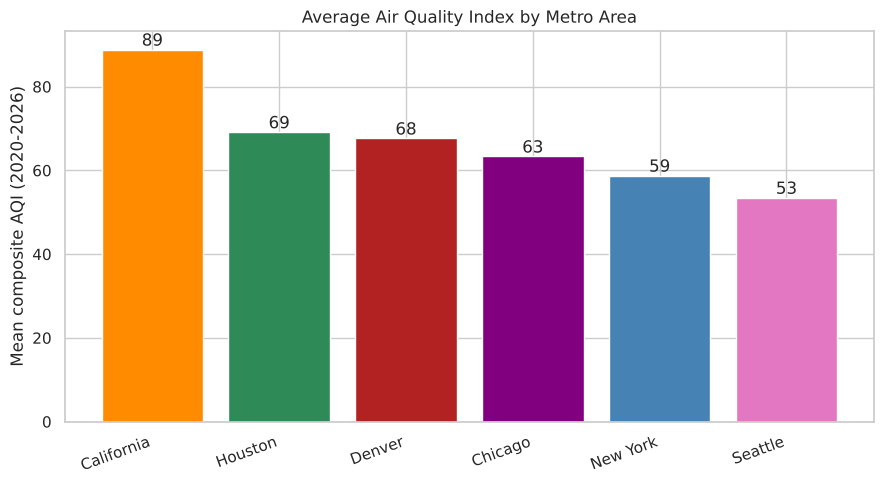

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
order = summary.sort_values("mean_aqi", ascending=False).index
bars = ax.bar(order, summary.loc[order, "mean_aqi"], color=[CITY_COLOR[c] for c in order])
ax.set_ylabel("Mean composite AQI (2020-2026)")
ax.set_title("Average Air Quality Index by Metro Area")
ax.bar_label(bars, fmt="%.0f")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("images/fig3a_mean_aqi_by_city.png", dpi=150, bbox_inches="tight")
plt.show()


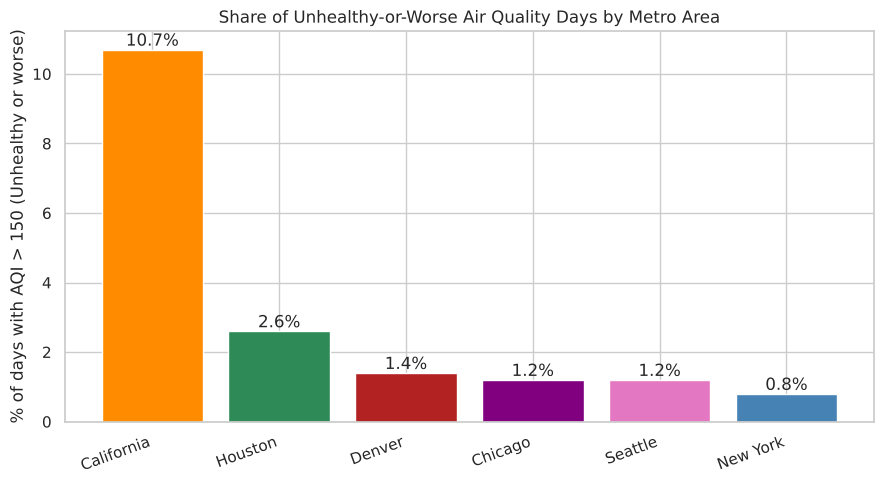

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
order = summary.sort_values("pct_days_unhealthy", ascending=False).index
bars = ax.bar(order, summary.loc[order, "pct_days_unhealthy"], color=[CITY_COLOR[c] for c in order])
ax.set_ylabel("% of days with AQI > 150 (Unhealthy or worse)")
ax.set_title("Share of Unhealthy-or-Worse Air Quality Days by Metro Area")
ax.bar_label(bars, fmt="%.1f%%")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("images/fig3b_pct_unhealthy_days.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Per-City Detail

Same three charts for every city, generated in a loop over `regions.csv`
so a 7th city only requires adding a row there and re-running — no copy-
pasted per-city cells.

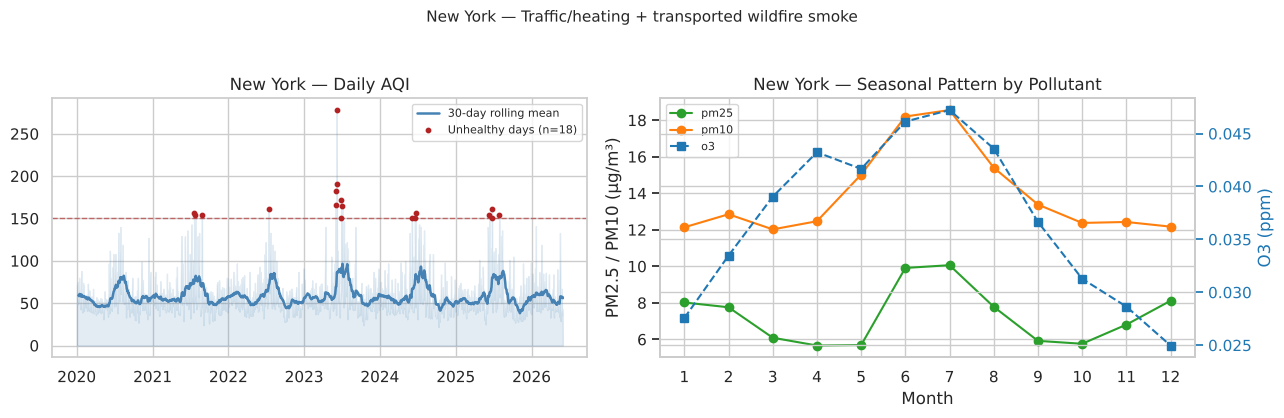

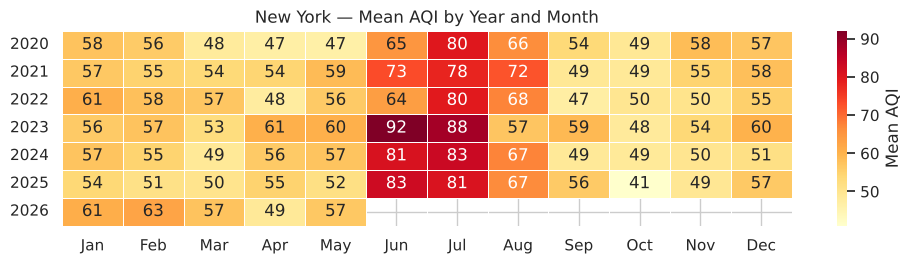


Top 10 worst AQI days — New York:
      date  aqi_composite   aqi_category aqi_defining_parameter
2023-06-07            278 Very Unhealthy                  PM2.5
2023-06-08            191      Unhealthy                  PM2.5
2023-06-06            183      Unhealthy                  PM2.5
2023-06-30            172      Unhealthy                  Ozone
2023-06-02            166      Unhealthy                  Ozone
2023-07-04            165      Unhealthy                  PM2.5
2022-07-14            161      Unhealthy                  Ozone
2025-06-24            161      Unhealthy                  Ozone
2021-07-20            156      Unhealthy                  PM2.5
2024-06-21            156      Unhealthy                  Ozone




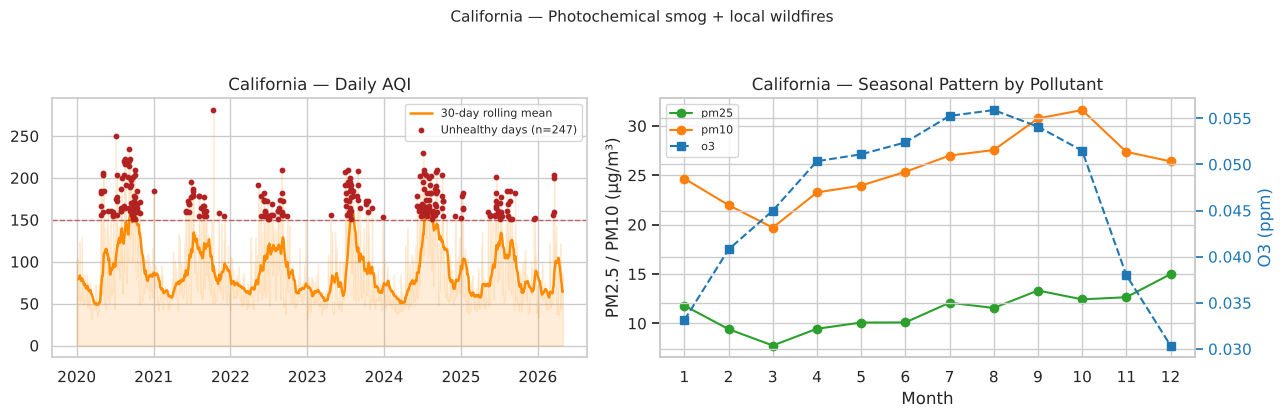

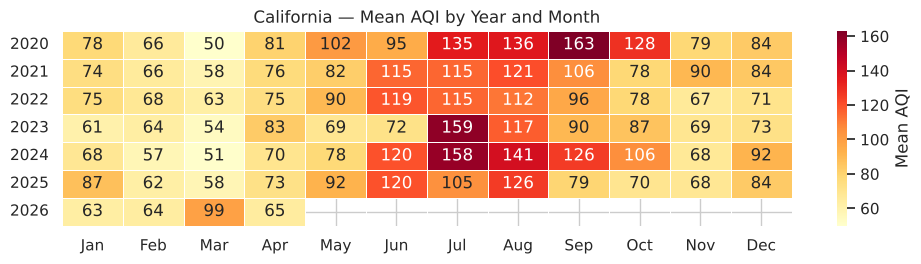


Top 10 worst AQI days — California:
      date  aqi_composite   aqi_category aqi_defining_parameter
2021-10-11            281 Very Unhealthy                   PM10
2020-07-05            250 Very Unhealthy                  PM2.5
2020-09-05            235 Very Unhealthy                  Ozone
2024-07-05            230 Very Unhealthy                  PM2.5
2020-09-11            223 Very Unhealthy                  PM2.5
2020-08-18            222 Very Unhealthy                  Ozone
2020-09-04            220 Very Unhealthy                  Ozone
2020-08-15            220 Very Unhealthy                  Ozone
2020-08-20            218 Very Unhealthy                  Ozone
2020-08-19            217 Very Unhealthy                  Ozone




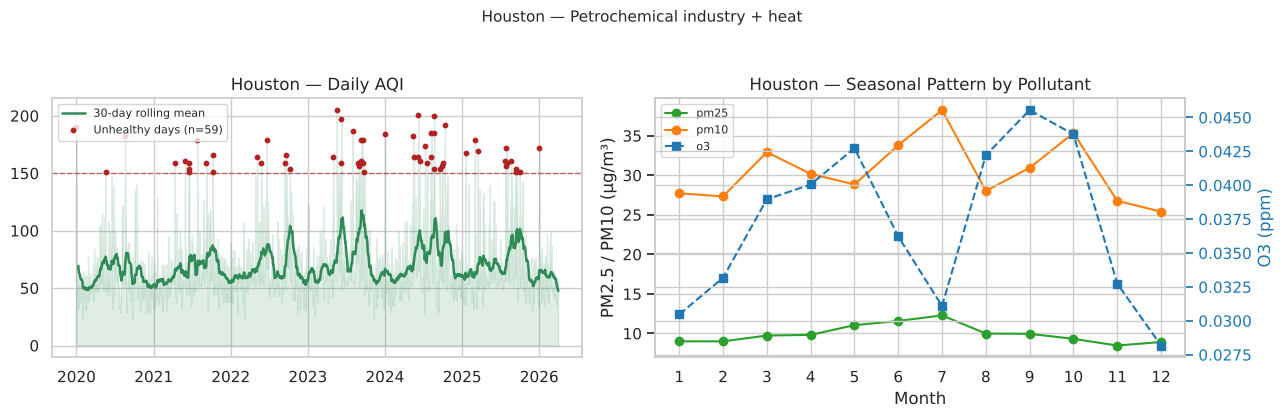

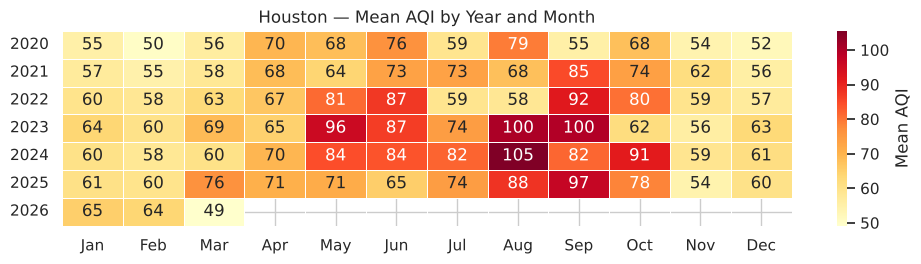


Top 10 worst AQI days — Houston:
      date  aqi_composite   aqi_category aqi_defining_parameter
2023-05-18            205 Very Unhealthy                  Ozone
2024-06-07            201 Very Unhealthy                  Ozone
2024-08-21            200      Unhealthy                  Ozone
2023-06-09            197      Unhealthy                  Ozone
2024-10-11            192      Unhealthy                  Ozone
2020-01-01            190      Unhealthy                  PM2.5
2023-08-01            187      Unhealthy                  Ozone
2024-08-08            185      Unhealthy                  Ozone
2024-08-22            185      Unhealthy                  Ozone
2024-01-01            184      Unhealthy                  PM2.5




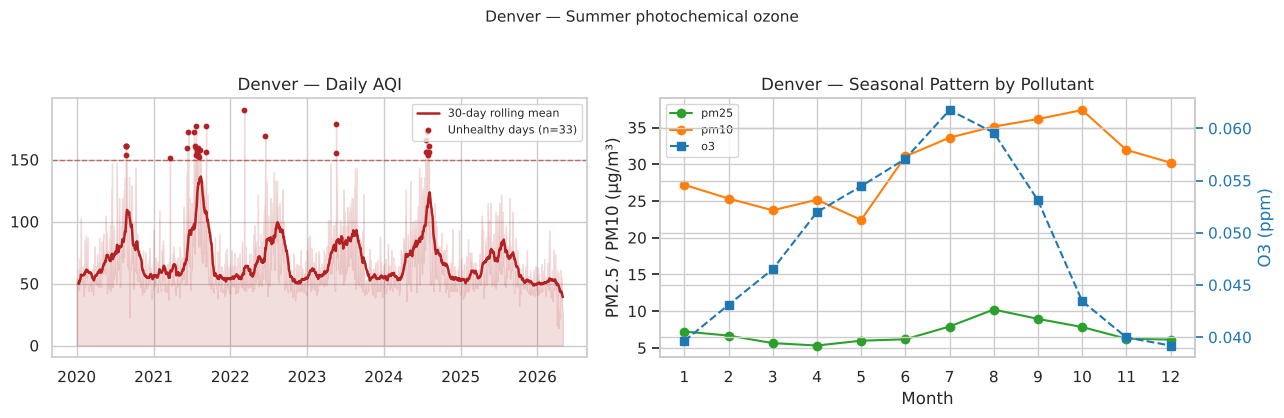

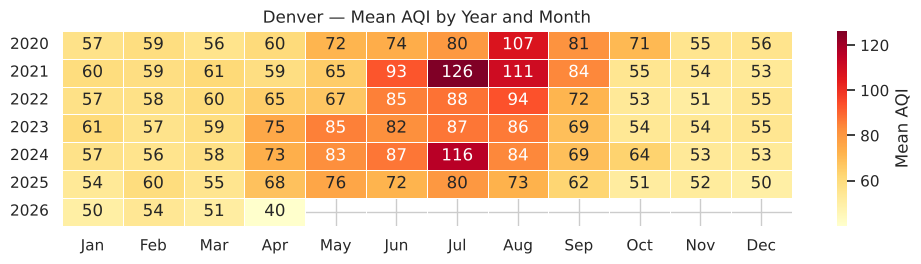


Top 10 worst AQI days — Denver:
      date  aqi_composite aqi_category aqi_defining_parameter
2022-03-08            190    Unhealthy                  Ozone
2023-05-19            179    Unhealthy                  PM2.5
2021-07-22            177    Unhealthy                  Ozone
2021-09-08            177    Unhealthy                  Ozone
2024-07-24            174    Unhealthy                  Ozone
2021-06-15            172    Unhealthy                  Ozone
2024-07-23            172    Unhealthy                  Ozone
2021-07-12            172    Unhealthy                  Ozone
2022-06-16            169    Unhealthy                  Ozone
2024-07-22            166    Unhealthy                  Ozone




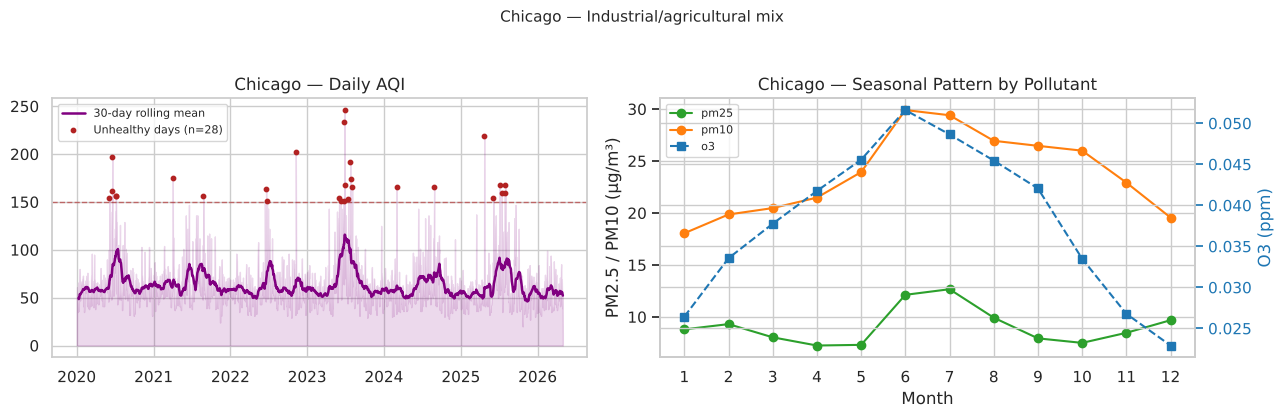

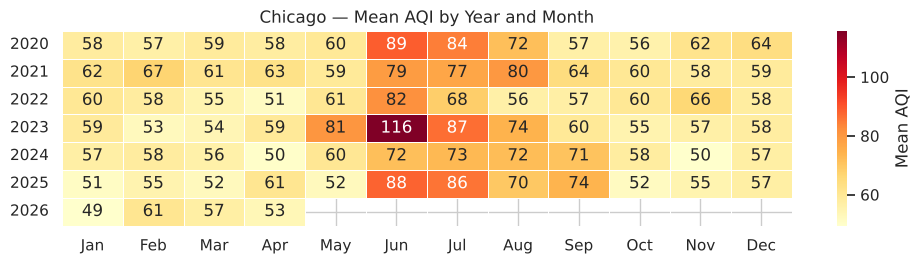


Top 10 worst AQI days — Chicago:
      date  aqi_composite   aqi_category aqi_defining_parameter
2023-06-28            246 Very Unhealthy                  PM2.5
2023-06-27            234 Very Unhealthy                  PM2.5
2025-04-22            219 Very Unhealthy                  PM2.5
2022-11-08            202 Very Unhealthy                  PM2.5
2020-06-19            197      Unhealthy                  Ozone
2023-07-25            192      Unhealthy                  Ozone
2021-04-02            175      Unhealthy                  PM2.5
2023-07-27            174      Unhealthy                  Ozone
2023-06-29            168      Unhealthy                  PM2.5
2025-07-04            168      Unhealthy                  PM2.5




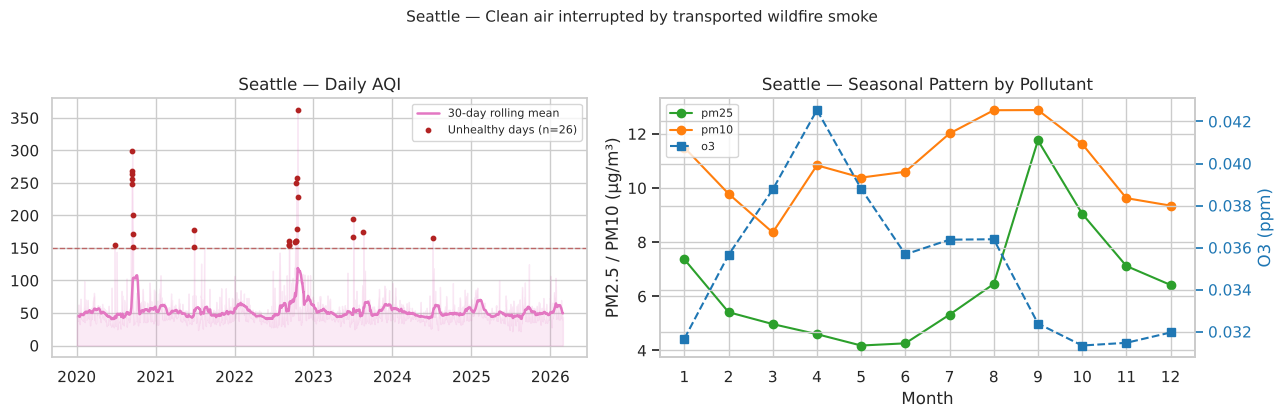

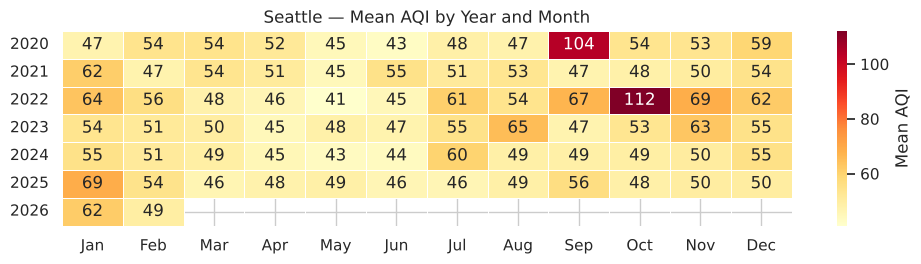


Top 10 worst AQI days — Seattle:
      date  aqi_composite   aqi_category aqi_defining_parameter
2022-10-19            362      Hazardous                  PM2.5
2020-09-14            299 Very Unhealthy                  PM2.5
2020-09-15            268 Very Unhealthy                  PM2.5
2020-09-13            263 Very Unhealthy                  PM2.5
2022-10-18            257 Very Unhealthy                  PM2.5
2020-09-12            256 Very Unhealthy                  PM2.5
2022-10-14            250 Very Unhealthy                  PM2.5
2020-09-11            248 Very Unhealthy                  PM2.5
2022-10-20            229 Very Unhealthy                  PM2.5
2020-09-16            200      Unhealthy                  PM2.5




In [7]:
def plot_city(city, mechanism, color):
    city_pollutants = pollutants[pollutants["city"] == city]
    city_aqi = aqi[aqi["city"] == city].copy()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Daily AQI: filled area + 30-day rolling mean + exceedance days highlighted,
    # instead of a plain thin background line — makes both the noise level
    # and the specific bad days visible in the same chart.
    daily = city_aqi.set_index("date")["aqi_composite"].sort_index()
    axes[0].fill_between(daily.index, daily.values, alpha=0.15, color=color)
    axes[0].plot(daily.index, daily.rolling(30, min_periods=10).mean(), color=color, linewidth=1.8, label="30-day rolling mean")
    exceed = daily[daily > 150]
    axes[0].scatter(exceed.index, exceed.values, color="firebrick", s=10, zorder=5, label=f"Unhealthy days (n={len(exceed)})")
    axes[0].axhline(150, color="firebrick", linestyle="--", linewidth=1, alpha=0.6)
    axes[0].set_title(f"{city} — Daily AQI")
    axes[0].legend(fontsize=8)

    # Monthly seasonality per pollutant — O3 (ppm) and PM2.5/PM10 (µg/m³) are
    # on very different scales, so O3 needs its own axis or it disappears
    # flat against zero next to the particulate values.
    monthly = (
        city_pollutants.assign(month=city_pollutants["date"].dt.month)
        .groupby(["month", "pollutant"])["value"]
        .mean()
        .unstack("pollutant")
    )
    ax_pm = axes[1]
    ax_o3 = ax_pm.twinx()

    for pol, pcolor in [("pm25", "tab:green"), ("pm10", "tab:orange")]:
        if pol in monthly.columns:
            ax_pm.plot(monthly.index, monthly[pol], marker="o", color=pcolor, label=pol)
    if "o3" in monthly.columns:
        ax_o3.plot(monthly.index, monthly["o3"], marker="s", color="tab:blue", linestyle="--", label="o3")

    ax_pm.set_ylabel("PM2.5 / PM10 (µg/m³)")
    ax_o3.set_ylabel("O3 (ppm)", color="tab:blue")
    ax_o3.tick_params(axis="y", colors="tab:blue")
    lines1, labels1 = ax_pm.get_legend_handles_labels()
    lines2, labels2 = ax_o3.get_legend_handles_labels()
    ax_pm.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc="upper left")
    ax_pm.set_title(f"{city} — Seasonal Pattern by Pollutant")
    ax_pm.set_xlabel("Month")
    ax_pm.set_xticks(range(1, 13))

    fig.suptitle(f"{city} — {mechanism}", fontsize=11, y=1.04)
    plt.tight_layout()
    plt.show()

    # Year x month AQI heatmap — shows directly whether a seasonal spike
    # repeats every year (a real pattern) or is driven by a single year
    # (an event, not a pattern) — exactly the question the June 2023
    # NY/Chicago spike raised in Section 4's line chart.
    city_aqi["year"] = city_aqi["date"].dt.year
    city_aqi["month"] = city_aqi["date"].dt.month
    pivot = city_aqi.pivot_table(index="year", columns="month", values="aqi_composite", aggfunc="mean")
    # Months with fewer than 5 days of data (the last, partly observed month of
    # the series) are left blank, as in the dashboard: a mean over 1-2 days is
    # not a monthly value and would distort the colour scale.
    n_days = city_aqi.pivot_table(index="year", columns="month", values="aqi_composite", aggfunc="count")
    pivot = pivot.where(n_days >= 5)
    pivot.columns = [["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"][m-1] for m in pivot.columns]

    fig, ax = plt.subplots(figsize=(10, 2.8))
    sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=0.5,
                cbar_kws={"label": "Mean AQI"}, ax=ax)
    ax.set_title(f"{city} — Mean AQI by Year and Month")
    ax.set_ylabel("")
    plt.tight_layout()
    safe_city = city.replace(" ", "_")
    plt.savefig(f"images/fig4_{safe_city}_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

    top10 = city_aqi.sort_values("aqi_composite", ascending=False).head(10)
    print(f"\nTop 10 worst AQI days — {city}:")
    print(top10[["date", "aqi_composite", "aqi_category", "aqi_defining_parameter"]].to_string(index=False))
    print("\n" + "=" * 90 + "\n")


for _, row in regions.iterrows():
    plot_city(row["city"], row["mechanism"], row["color"])


## 5. County-Level Detail Within Each CBSA

The comparison above treats each CBSA as one unit. But a CBSA is several
counties — this section checks whether pollution is spread evenly across
a metro area or concentrated in a few counties, using the `county` column
already loaded in `pollutants` but not used until now.

In [8]:
for city in CITY_ORDER:
    city_data = pollutants[(pollutants["city"] == city) & (pollutants["county"].notna())]
    if city_data.empty:
        print(f"{city}: no county-level data available\n")
        continue

    county_means = (
        city_data.groupby(["county", "pollutant"])["value"]
        .mean()
        .unstack("pollutant")
    )
    # Sort consistently by PM2.5 (falling back to PM10, then O3) rather than
    # by whichever pollutant happens to have the most raw rows for that
    # city — sorting by the most-frequent pollutant meant Houston/Denver
    # were effectively sorted by O3, which on a µg/m³-scaled rounding
    # would display as ~0.0 for every county and make the ranking useless.
    sort_col = next((p for p in ["pm25", "pm10", "o3"] if p in county_means.columns), None)
    if sort_col:
        county_means = county_means.sort_values(by=sort_col, ascending=False)

    n_counties = city_data["county"].nunique()
    print(f"{city} — {n_counties} counties reporting (sorted by {sort_col}, showing up to 10)")
    # O3 is on a ppm scale (~0.02-0.08) vs µg/m³ for PM2.5/PM10 — round each
    # column to a precision that keeps it readable instead of a uniform
    # .round(1) that flattens O3 to 0.0 everywhere.
    # Show up to 10 rows (not 5) so the "spread out vs concentrated"
    # claim in the conclusions can actually be checked against this output.
    display_table = county_means.head(10).copy()
    for col in display_table.columns:
        display_table[col] = display_table[col].round(3 if col == "o3" else 1)
    print(display_table.to_string())
    print()


New York — 22 counties reporting (sorted by pm25, showing up to 10)
pollutant     o3  pm10  pm25
county                      
Union        NaN   NaN   8.6
Essex      0.035  13.6   8.5
Bergen     0.040   NaN   8.0
Kings        NaN   NaN   7.9
Hunterdon  0.038   NaN   7.7
New York   0.035  12.9   7.6
Queens     0.037  12.9   7.6
Bronx      0.036  13.2   7.5
Hudson     0.035  15.2   7.5
Passaic    0.040   NaN   7.3

California — 2 counties reporting (sorted by pm25, showing up to 10)
pollutant       o3  pm10  pm25
county                        
Los Angeles  0.047  26.0  11.4
Orange       0.043  24.1  10.4

Houston — 4 counties reporting (sorted by pm25, showing up to 10)
pollutant      o3  pm10  pm25
county                       
Harris      0.037  31.4  10.2
Montgomery  0.042   NaN  10.0
Galveston   0.040  19.1   7.9
Brazoria    0.036   NaN   7.8

Denver — 8 counties reporting (sorted by pm25, showing up to 10)
pollutant       o3  pm10  pm25
county                        
Denver       0.

### 5.2 Population-Weighted Exposure: Person-Days of PM2.5 Exceedance

Raw exceedance counts treat a bad air day in Denver (population ~2.9M in the CBSA)
the same as one in Los Angeles (population ~13.1M). For climate risk analysis, what
matters is **how many people were actually exposed** — a metric known as person-days
of exceedance.

Population data: US Census Bureau, ACS 5-Year Estimates 2022 (variable B01003_001E),
downloaded via Census Data API. County-level population is summed over the counties
included for each metro area in this project (New York 22, Chicago 8, Denver 8,
Houston 4, Seattle 3, Los Angeles 2). That county list follows this project's own
region mapping and may not match the Census Bureau's official CBSA delineation
exactly (some outlying counties may be omitted), so the "CBSA population" used for
per-capita figures is the population of the included counties.

Exceedance threshold: EPA 24-hour PM2.5 NAAQS of 35 µg/m³ (applied to daily mean
concentrations from EPA AQS monitors). Days where any monitor in a county exceeded
this threshold are counted once per county per day (not per monitor), to avoid
double-counting from overlapping monitoring networks.

In [9]:
import requests
import os
from dotenv import load_dotenv

CSV_PATH = Path("data/external/county_population.csv")

if CSV_PATH.exists():
    # CSV already downloaded — load directly without needing the API key
    pop_df = pd.read_csv(CSV_PATH)
    print(f"Loaded {len(pop_df)} counties from {CSV_PATH}")
    for _, row in pop_df.iterrows():
        print(f"✓ {row['county']} ({row['city']}): {row['population']:,}")
else:
    # First run — download from Census API
    load_dotenv(override=True)
    CENSUS_KEY = os.environ.get("CENSUS_KEY", "")
    if not CENSUS_KEY:
        raise ValueError("CENSUS_KEY not found in .env — add it to the project root")

    COUNTIES = [
        ("34", "039", "Union", "New York"),
        ("34", "013", "Essex", "New York"),
        ("34", "003", "Bergen", "New York"),
        ("36", "047", "Kings", "New York"),
        ("34", "019", "Hunterdon", "New York"),
        ("36", "061", "New York", "New York"),
        ("36", "081", "Queens", "New York"),
        ("36", "005", "Bronx", "New York"),
        ("34", "017", "Hudson", "New York"),
        ("34", "031", "Passaic", "New York"),
        ("36", "027", "Dutchess", "New York"),
        ("36", "059", "Nassau", "New York"),
        ("36", "071", "Orange", "New York"),
        ("36", "079", "Putnam", "New York"),
        ("36", "085", "Richmond", "New York"),
        ("36", "087", "Rockland", "New York"),
        ("36", "103", "Suffolk", "New York"),
        ("36", "119", "Westchester", "New York"),
        ("34", "023", "Middlesex", "New York"),
        ("34", "025", "Monmouth", "New York"),
        ("34", "027", "Morris", "New York"),
        ("34", "029", "Ocean", "New York"),
        ("06", "037", "Los Angeles", "California"),
        ("06", "059", "Orange", "California"),
        ("48", "201", "Harris", "Houston"),
        ("48", "339", "Montgomery", "Houston"),
        ("48", "167", "Galveston", "Houston"),
        ("48", "039", "Brazoria", "Houston"),
        ("08", "031", "Denver", "Denver"),
        ("08", "001", "Adams", "Denver"),
        ("08", "035", "Douglas", "Denver"),
        ("08", "005", "Arapahoe", "Denver"),
        ("08", "019", "Clear Creek", "Denver"),
        ("08", "047", "Gilpin", "Denver"),
        ("08", "059", "Jefferson", "Denver"),
        ("08", "093", "Park", "Denver"),
        ("17", "043", "DuPage", "Chicago"),
        ("17", "031", "Cook", "Chicago"),
        ("17", "097", "Lake", "Chicago"),
        ("17", "089", "Kane", "Chicago"),
        ("17", "197", "Will", "Chicago"),
        ("17", "111", "McHenry", "Chicago"),
        ("18", "127", "Porter", "Chicago"),
        ("55", "059", "Kenosha", "Chicago"),
        ("53", "053", "Pierce", "Seattle"),
        ("53", "033", "King", "Seattle"),
        ("53", "061", "Snohomish", "Seattle"),
    ]

    BASE_URL = "https://api.census.gov/data/2022/acs/acs5"
    records = []
    for state_fips, county_fips, county_name, city in COUNTIES:
        url = (
            f"{BASE_URL}?get=B01003_001E,NAME"
            f"&for=county:{county_fips}"
            f"&in=state:{state_fips}"
            f"&key={CENSUS_KEY}"
        )
        r = requests.get(url)
        if r.status_code == 200:
            data = r.json()
            pop = int(data[1][0])
            records.append({
                "city": city,
                "county": county_name,
                "population": pop,
                "state_fips": state_fips,
                "county_fips": county_fips,
            })
            print(f"✓ {county_name} ({city}): {pop:,}")
        else:
            print(f"✗ {county_name} ({city}): HTTP {r.status_code}")

    pop_df = pd.DataFrame(records)
    Path("data/external").mkdir(exist_ok=True)
    pop_df.to_csv(CSV_PATH, index=False)
    print(f"\nSaved {len(pop_df)} counties to {CSV_PATH}")

# ── Patch for older local CSVs that only contain 10 New York counties ────────
# A fresh download (above) already includes all 22 New York counties. An older
# county_population.csv may contain only the first 10 (Kings, New York, Queens,
# Bronx + the NJ core). The 12 counties below are the missing ones (Census ACS
# 5-Year 2022, variable B01003_001E, values from the Census Data API).
# This block is idempotent: it checks before inserting, so re-running is safe.
_NY_MISSING = [
    {"city": "New York", "county": "Dutchess",   "population": 296467,  "state_fips": "36", "county_fips": "027"},
    {"city": "New York", "county": "Nassau",      "population": 1389160, "state_fips": "36", "county_fips": "059"},
    {"city": "New York", "county": "Orange",      "population": 401237,  "state_fips": "36", "county_fips": "071"},
    {"city": "New York", "county": "Putnam",      "population": 97942,   "state_fips": "36", "county_fips": "079"},
    {"city": "New York", "county": "Richmond",    "population": 492925,  "state_fips": "36", "county_fips": "085"},
    {"city": "New York", "county": "Rockland",    "population": 337326,  "state_fips": "36", "county_fips": "087"},
    {"city": "New York", "county": "Suffolk",     "population": 1524486, "state_fips": "36", "county_fips": "103"},
    {"city": "New York", "county": "Westchester", "population": 997904,  "state_fips": "36", "county_fips": "119"},
    {"city": "New York", "county": "Middlesex",   "population": 860147,  "state_fips": "34", "county_fips": "023"},
    {"city": "New York", "county": "Monmouth",    "population": 643064,  "state_fips": "34", "county_fips": "025"},
    {"city": "New York", "county": "Morris",      "population": 508816,  "state_fips": "34", "county_fips": "027"},
    {"city": "New York", "county": "Ocean",       "population": 638691,  "state_fips": "34", "county_fips": "029"},
]

_existing_ny = set(pop_df.loc[pop_df["city"] == "New York", "county"].str.strip())
_to_add = [r for r in _NY_MISSING if r["county"] not in _existing_ny]

if _to_add:
    pop_df = pd.concat([pop_df, pd.DataFrame(_to_add)], ignore_index=True)
    try:
        pop_df.to_csv(CSV_PATH, index=False)
        print(f"\nPatched county_population.csv: added {len(_to_add)} missing NY counties")
    except PermissionError:
        print("\nNote: could not save the CSV (file open in another program).")
        print(f"The {len(_to_add)} counties were added in memory, so the analysis continues with correct data.")
        print("Close any program that has county_population.csv open and re-run this cell to save it.")
    for r in _to_add:
        print(f"  + {r['county']} (NY metro): {r['population']:,}")
else:
    print("\nNY county patch: all 12 counties already present — no changes needed")

print(f"\nNew York counties in pop_df: {pop_df[pop_df['city'] == 'New York']['county'].tolist()}")
print(f"Total NY population: {pop_df[pop_df['city'] == 'New York']['population'].sum():,}")


Loaded 47 counties from data/external/county_population.csv
✓ Union (New York): 572,079
✓ Essex (New York): 853,374
✓ Bergen (New York): 953,243
✓ Kings (New York): 2,679,620
✓ Hunterdon (New York): 129,099
✓ New York (New York): 1,645,867
✓ Queens (New York): 2,360,826
✓ Bronx (New York): 1,443,229
✓ Hudson (New York): 712,029
✓ Passaic (New York): 519,986
✓ Los Angeles (California): 9,936,690
✓ Orange (California): 3,175,227
✓ Harris (Houston): 4,726,177
✓ Montgomery (Houston): 629,989
✓ Galveston (Houston): 350,801
✓ Brazoria (Houston): 374,600
✓ Denver (Denver): 710,800
✓ Adams (Denver): 520,149
✓ Douglas (Denver): 360,206
✓ Arapahoe (Denver): 654,453
✓ Clear Creek (Denver): 9,403
✓ Gilpin (Denver): 5,856
✓ Jefferson (Denver): 580,519
✓ Park (Denver): 17,597
✓ DuPage (Chicago): 930,559
✓ Cook (Chicago): 5,225,367
✓ Lake (Chicago): 713,159
✓ Kane (Chicago): 517,254
✓ Will (Chicago): 696,774
✓ McHenry (Chicago): 311,133
✓ Porter (Chicago): 173,355
✓ Kenosha (Chicago): 168,693
✓ Pierc

City,New York,California,Houston,Denver,Chicago,Seattle
Year,,,,,,
2020,1.4M,395.8M,15.8M,10.7M,12.2M,47.7M
2021,19.5M,213.8M,4.7M,10.8M,30.0M,7.0M
2022,0.0M,79.5M,9.8M,0.0M,1.1M,54.9M
2023,94.0M,42.9M,5.4M,5.5M,59.8M,14.3M
2024,5.0M,164.9M,17.3M,0.5M,0.7M,0.9M
2025,9.1M,188.0M,9.5M,0.0M,70.2M,1.7M
2026,2.9M,49.3M,9.5M,0.0M,40.9M,1.7M


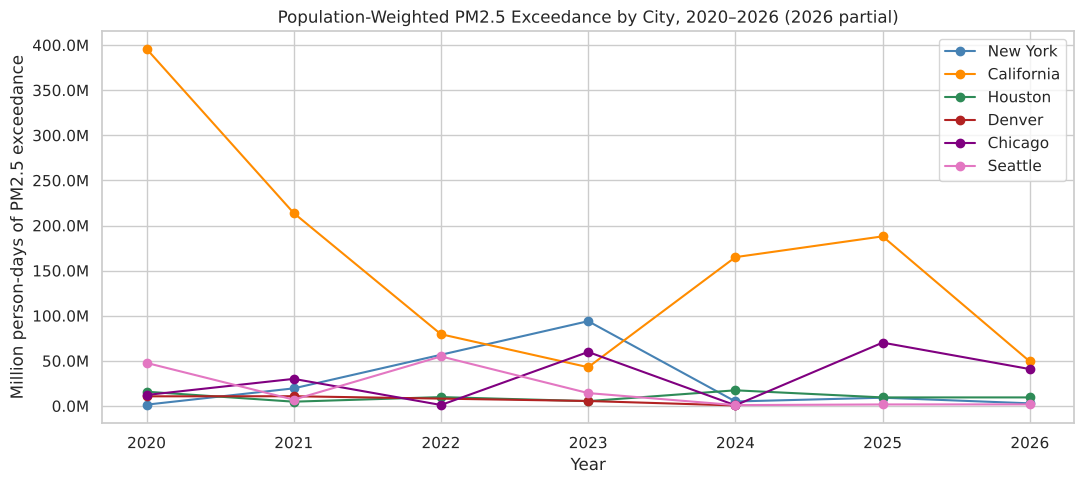

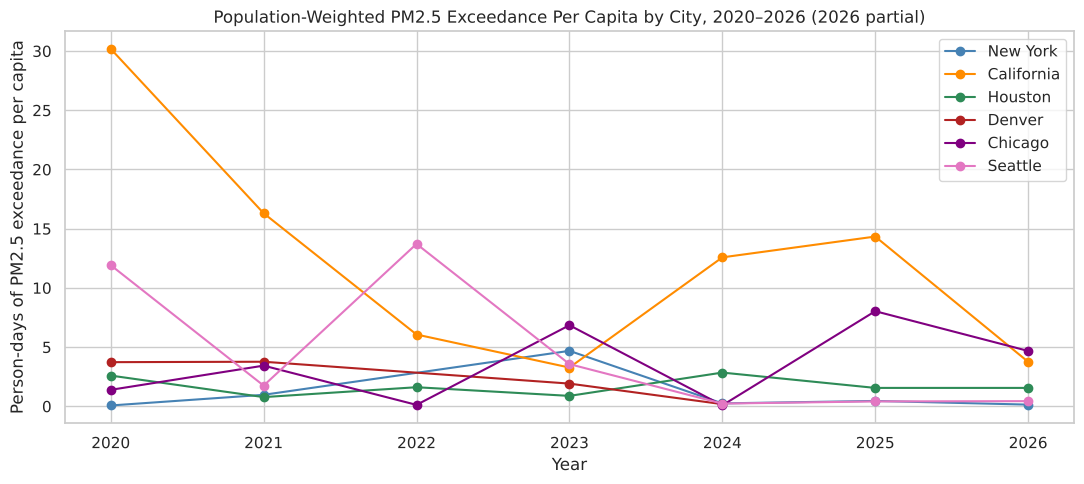


Key finding: person-days weight exceedances by actual population exposed,
not just by number of monitoring days — a more meaningful risk metric.


In [10]:
# pop_df comes from the county-population cell above (Section 5), incl. the NY patch

# Days per county where PM2.5 exceeded EPA threshold (35 µg/m³)
# using the raw pollutants data (station level, not CBSA aggregate)
pm25_raw = pollutants[pollutants["pollutant"] == "pm25"].copy()
pm25_raw["year"] = pm25_raw["date"].dt.year

exceed_days = (
    pm25_raw[pm25_raw["value"] > 35]
    .groupby(["city", "county", "year"])
    .agg(exceedance_days=("date", "nunique"))
    .reset_index()
)

# Merge with population
exceed_pop = exceed_days.merge(
    pop_df[["city", "county", "population"]],
    on=["city", "county"], how="left"
)
exceed_pop["person_days"] = (
    exceed_pop["exceedance_days"] * exceed_pop["population"]
)

# Summary per city per year
person_days_summary = (
    exceed_pop.groupby(["city", "year"])
    .agg(
        exceedance_days=("exceedance_days", "sum"),
        person_days=("person_days", "sum")
    )
    .reset_index()
)

pivot_pd_M = (person_days_summary.pivot(
    index="year", columns="city", values="person_days"
).fillna(0) / 1e6).round(1).reindex(columns=CITY_ORDER)

pivot_pd_M.columns.name = "City"
pivot_pd_M.index.name = "Year"
display(pivot_pd_M.style
    .format("{:.1f}M")
    .background_gradient(cmap="YlOrRd", axis=None)
    .set_caption("Person-days of PM2.5 exceedance, millions (EPA 24-hour threshold 35 µg/m³; 2026 is a partial year)")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "13px"), ("font-weight", "bold")]}
    ])
)


# Visualize
fig, ax = plt.subplots(figsize=(11, 5))
for city in CITY_ORDER:
    city_data = person_days_summary[person_days_summary["city"] == city]
    if len(city_data):
        ax.plot(city_data["year"], city_data["person_days"] / 1e6,
                marker="o", label=city, color=CITY_COLOR[city])
ax.set_ylabel("Million person-days of PM2.5 exceedance")
ax.set_title("Population-Weighted PM2.5 Exceedance by City, 2020–2026 (2026 partial)")
ax.set_xlabel("Year")
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1f}M"))
plt.tight_layout()
plt.show()

# Per-capita line chart
fig2, ax2 = plt.subplots(figsize=(11, 5))
cbsa_pop_52 = pop_df.groupby("city")["population"].sum().reset_index()
cbsa_pop_52.columns = ["city", "cbsa_population"]
pd_percapita = person_days_summary.merge(cbsa_pop_52, on="city", how="left")
pd_percapita["person_days_per_capita"] = pd_percapita["person_days"] / pd_percapita["cbsa_population"]

for city in CITY_ORDER:
    city_data = pd_percapita[pd_percapita["city"] == city]
    if len(city_data) and city_data["person_days_per_capita"].sum() > 0:
        ax2.plot(city_data["year"], city_data["person_days_per_capita"],
                 marker="o", label=city, color=CITY_COLOR[city])
ax2.set_ylabel("Person-days of PM2.5 exceedance per capita")
ax2.set_title("Population-Weighted PM2.5 Exceedance Per Capita by City, 2020–2026 (2026 partial)")
ax2.set_xlabel("Year")
ax2.set_xticks(list(range(2020, 2027)))
ax2.legend()
plt.tight_layout()
plt.show()

print("\nKey finding: person-days weight exceedances by actual population exposed,")
print("not just by number of monitoring days — a more meaningful risk metric.")

## 6. Documented Events: Wind Context

For the 7 events identified from the AQI data itself (largest sustained
clusters of AQI > 150 per city, not just the single worst day — see
`events.csv`), here is the surface wind context. Wind direction
uses a circular mean (not a plain arithmetic mean, which gives nonsensical
results for compass degrees), and for the two events where the exact
smoke-transport days are known, the window is narrowed to those specific
days rather than the full month average.

**Note on methodology:** these events are the month with the most days
over the AQI 150 threshold (a sustained bad month), not necessarily the
month containing the single most extreme day (Section 4's top-10). For
California and Houston specifically, the documented event month does not
overlap with any date in that city's own top-10 table — that is expected,
not a data error: California's July 2023 had 20 moderately bad days but
none extreme enough to beat 2020's sharper spikes, and the same logic
applies to Houston's September 2023. Read "worst sustained month" and
"single worst day" as two different questions, not one.

In [11]:
def circular_mean_deg(degrees):
    """Correct average for wind direction (a circular variable).
    Averaging compass degrees directly gives nonsensical results
    whenever values cross the 0/360 boundary."""
    radians = np.deg2rad(degrees.dropna())
    sin_mean = np.sin(radians).mean()
    cos_mean = np.cos(radians).mean()
    return (np.degrees(np.arctan2(sin_mean, cos_mean)) + 360) % 360


# Narrow to the exact event days where known (not the full month average,
# which dilutes a 2-3 day transport event with 27-28 unrelated days).
EVENT_DAY_RANGES = {
    ("New York", 2023, 6): ("2023-06-06", "2023-06-08"),
    ("Chicago", 2023, 6): ("2023-06-27", "2023-06-28"),
}

for _, ev in events.iterrows():
    city, year, month, label = ev["city"], ev["event_year"], ev["event_month"], ev["event_label"]
    key = (city, year, month)

    if key in EVENT_DAY_RANGES:
        start, end = EVENT_DAY_RANGES[key]
        sub = meteo[(meteo["city"] == city) & (meteo["date"] >= start) & (meteo["date"] <= end)]
        window_label = f"{start} to {end} (event days only)"
    else:
        sub = meteo[(meteo["city"] == city) & (meteo["date"].dt.year == year) & (meteo["date"].dt.month == month)]
        window_label = f"{year}-{month:02d} (full month, no exact event days recorded)"

    if sub.empty:
        print(f"{city} {year}-{month:02d} ({label}): no meteo data loaded — check events.csv / data files")
        continue

    wind_speed = sub[sub["parameter"] == "Wind Speed - Resultant"]["value"]
    wind_dir = sub[sub["parameter"] == "Wind Direction - Resultant"]["value"]

    # Print the days-over-threshold count that justifies this event being
    # picked, so the "most sustained bad month" claim is traceable to an
    # output rather than asserted in prose.
    month_aqi = aqi[(aqi["city"] == city) & (aqi["date"].dt.year == year) & (aqi["date"].dt.month == month)]
    n_over = (month_aqi["aqi_composite"] > 150).sum()
    max_in_month = month_aqi["aqi_composite"].max() if len(month_aqi) else float("nan")

    print(f"{city} — {label} — window: {window_label}")
    print(f"  Days over AQI 150 that month: {n_over} (month max AQI: {max_in_month:.0f})")
    if len(wind_speed):
        print(f"  Wind speed: mean {wind_speed.mean():.1f} kt, max {wind_speed.max():.1f} kt")
    if len(wind_dir):
        print(f"  Wind direction (circular mean): {circular_mean_deg(wind_dir):.0f}° compass")
    print()


New York — Quebec wildfire smoke — window: 2023-06-06 to 2023-06-08 (event days only)
  Days over AQI 150 that month: 6 (month max AQI: 278)
  Wind speed: mean 4.2 kt, max 6.9 kt
  Wind direction (circular mean): 247° compass

Chicago — Quebec wildfire smoke — window: 2023-06-27 to 2023-06-28 (event days only)
  Days over AQI 150 that month: 6 (month max AQI: 246)
  Wind speed: mean 4.9 kt, max 10.4 kt
  Wind direction (circular mean): 147° compass

California — Summer ozone cluster — window: 2023-07 (full month, no exact event days recorded)
  Days over AQI 150 that month: 20 (month max AQI: 210)
  Wind speed: mean 2.8 kt, max 5.6 kt
  Wind direction (circular mean): 198° compass

Houston — Summer ozone cluster — window: 2023-09 (full month, no exact event days recorded)
  Days over AQI 150 that month: 6 (month max AQI: 179)
  Wind speed: mean 4.0 kt, max 13.3 kt
  Wind direction (circular mean): 154° compass

Denver — Summer ozone cluster — window: 2021-07 (full month, no exact event

## 7. Cross-City Correlations

PM2.5 vs PM10 (do particulate events move together within each city?) and
seasonal offset between PM2.5 and O3 (winter-peak vs summer-peak pattern
across mechanisms).

New York     paired PM2.5/PM10 city-days:   512   Pearson r = 0.85
California   paired PM2.5/PM10 city-days: 2,400   Pearson r = 0.63
Houston      paired PM2.5/PM10 city-days: 1,792   Pearson r = 0.48


Denver       paired PM2.5/PM10 city-days: 2,389   Pearson r = 0.52
Chicago      paired PM2.5/PM10 city-days: 2,400   Pearson r = 0.70
Seattle      paired PM2.5/PM10 city-days: 1,231   Pearson r = 0.72


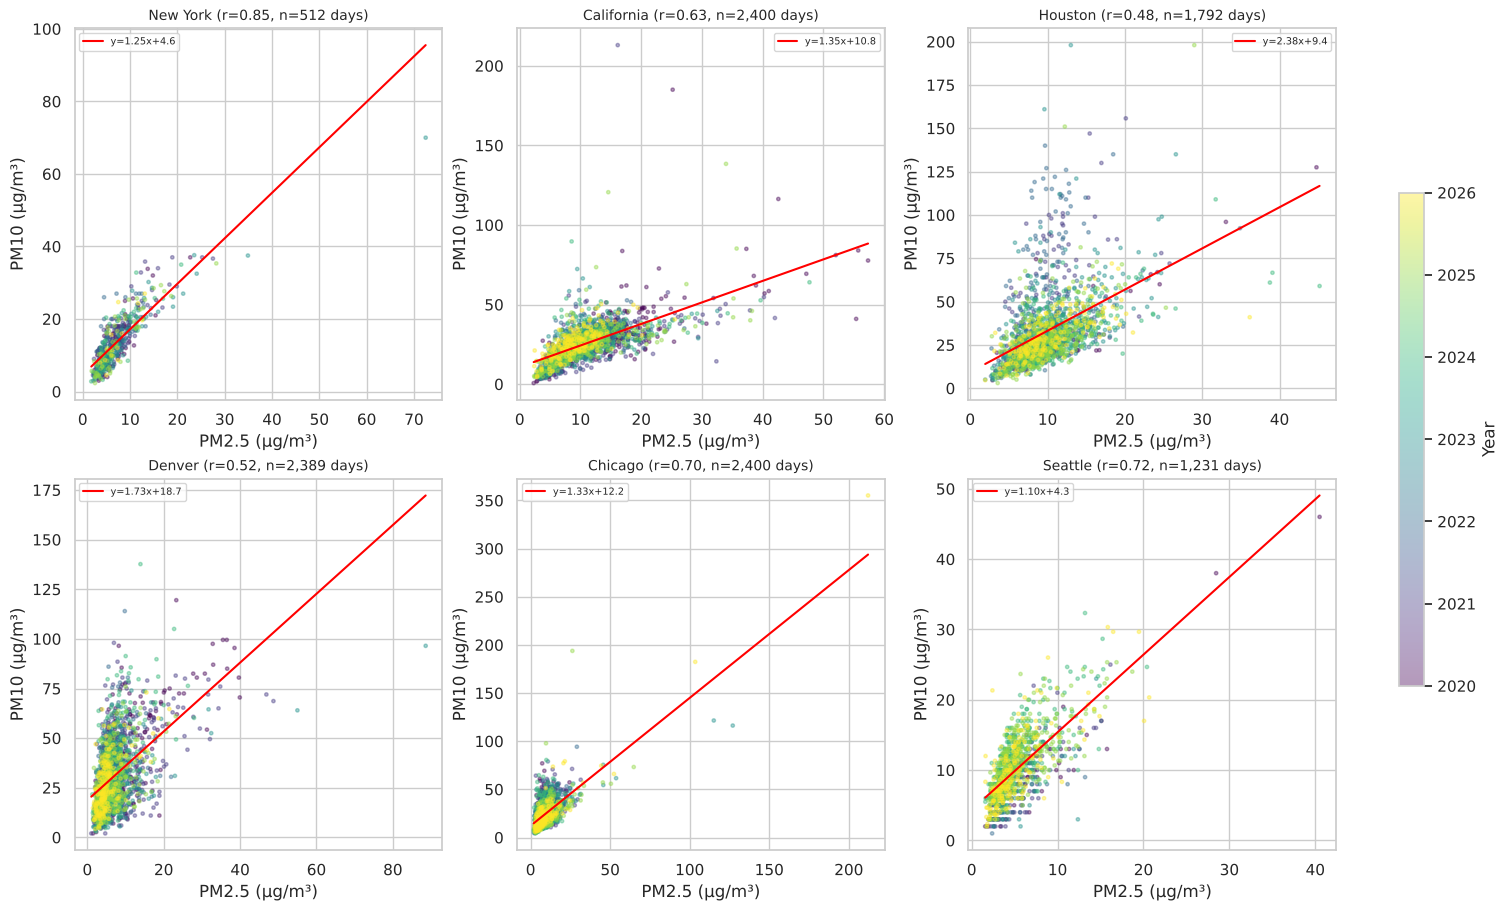

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
for ax, city in zip(axes.flat, CITY_ORDER):
    city_data = pollutants[pollutants["city"] == city]
    wide = city_data.pivot_table(index="date", columns="pollutant", values="value")
    if {"pm25", "pm10"}.issubset(wide.columns):
        valid = wide[["pm25", "pm10"]].dropna().reset_index()
        valid["year"] = pd.to_datetime(valid["date"]).dt.year
        n_pairs = len(valid)  # city-days with BOTH PM2.5 and PM10 (not raw row counts)
        r = valid["pm25"].corr(valid["pm10"]) if n_pairs > 10 else float("nan")
        print(f"{city:<12} paired PM2.5/PM10 city-days: {n_pairs:>5,}   Pearson r = {r:.2f}")

        scatter = ax.scatter(valid["pm25"], valid["pm10"], c=valid["year"], cmap="viridis", s=6, alpha=0.4)

        if n_pairs >= 3:
            m, b = np.polyfit(valid["pm25"], valid["pm10"], 1)
            x_line = np.linspace(valid["pm25"].min(), valid["pm25"].max(), 100)
            ax.plot(x_line, m * x_line + b, color="red", linewidth=1.5, label=f"y={m:.2f}x+{b:.1f}")

        ax.set_title(f"{city} (r={r:.2f}, n={n_pairs:,} days)", fontsize=10)
        ax.set_xlabel("PM2.5 (µg/m³)")
        ax.set_ylabel("PM10 (µg/m³)")
        ax.legend(fontsize=7)
    else:
        ax.set_visible(False)

fig.colorbar(scatter, ax=axes, label="Year", shrink=0.6)
plt.savefig("images/fig7_pm25_pm10_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


In [13]:
# Seasonal offset: does each city's PM2.5 peak in a different month than
# its O3 peak? This is the second analysis promised in this section's
# intro (PM2.5 is expected to peak in winter for traffic/heating-driven
# cities, O3 in summer for photochemical ones) — computed explicitly here
# instead of only asserted in prose.
#
# CAVEAT: this uses all years including 2023. Section 10 checks whether
# NY/Chicago's actual computed peak month (not an assumed month) is a
# real recurring pattern or is pulled up by the single June 2023
# wildfire event — read this table together with Section 10's output,
# not in isolation.
offset_rows = []
for city in CITY_ORDER:
    city_data = pollutants[pollutants["city"] == city].copy()
    city_data["month"] = city_data["date"].dt.month
    monthly_mean = city_data.groupby(["pollutant", "month"])["value"].mean()

    row = {"city": city}
    for pol in ["pm25", "o3"]:
        if pol in monthly_mean.index.get_level_values(0):
            peak_month = monthly_mean.loc[pol].idxmax()
            row[f"{pol}_peak_month"] = peak_month
    if "pm25_peak_month" in row and "o3_peak_month" in row:
        diff = abs(row["pm25_peak_month"] - row["o3_peak_month"])
        row["month_gap"] = min(diff, 12 - diff)  # circular distance, max 6
    offset_rows.append(row)

offset_df = pd.DataFrame(offset_rows).set_index("city").reindex(CITY_ORDER)
print("Month each pollutant peaks in, and the gap between them (0=same month, 6=opposite season):")
print(offset_df)


Month each pollutant peaks in, and the gap between them (0=same month, 6=opposite season):
            pm25_peak_month  o3_peak_month  month_gap
city                                                 
New York                  7              7          0
California               12              8          4
Houston                   7              9          2
Denver                    8              7          1
Chicago                   7              6          1
Seattle                   9              4          5


## 8. Year-Over-Year Trend

Is each city's air quality improving, worsening, or flat across the
complete years 2020–2025? The charts and top-10 tables above only show
relative ranking and seasonal shape, never whether a city is trending in
either direction over time.

2026 is **excluded** from the trend analysis. It is a partial year whose
cut-off differs by city (Section 1), so its annual mean covers only some
seasons and would bias the comparison (for example, a year that contains no
autumn wildfire or late-summer ozone months looks artificially clean).


Mean annual AQI by city. 2026 is a PARTIAL year (different cut-off per city):
shown for reference only, not comparable with full years and excluded from Section 8.2.

city  New York  California  Houston  Denver  Chicago  Seattle
year                                                         
2020      57.1        99.8     62.0    69.0     64.5     54.9
2021      59.4        89.0     66.0    73.4     65.8     51.4
2022      57.8        85.8     68.5    67.0     61.0     60.4
2023      62.2        83.4     74.6    68.7     67.6     52.8
2024      58.8        94.6     74.9    71.1     61.2     50.0
2025      58.0        85.5     71.4    62.7     62.7     50.9
2026      56.9        73.0     58.5    48.5     54.6     55.8


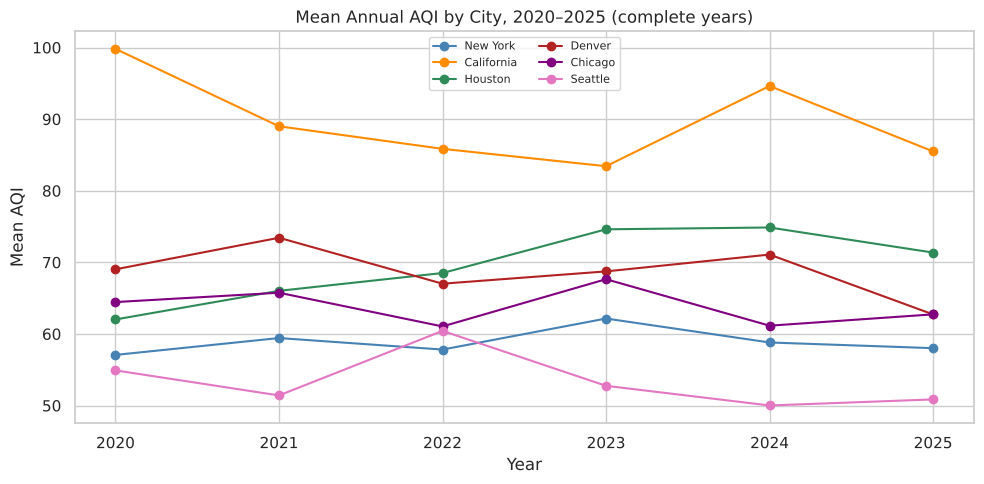

In [14]:
yearly = (
    aqi.assign(year=aqi["date"].dt.year)
    .groupby(["year", "city"])["aqi_composite"]
    .mean()
    .unstack("city")
    .reindex(columns=CITY_ORDER)
)
# 2026 is a partial year with a different cut-off per city (see the coverage
# table in Section 1). It is printed for reference but excluded from the
# chart and from the trend test, because a partial year only covers some seasons.
print("Mean annual AQI by city. 2026 is a PARTIAL year (different cut-off per city):")
print("shown for reference only, not comparable with full years and excluded from Section 8.2.\n")
print(yearly.round(1))

yearly_full = yearly.loc[yearly.index <= 2025]

fig, ax = plt.subplots(figsize=(10, 5))
for city in CITY_ORDER:
    ax.plot(yearly_full.index, yearly_full[city], marker="o", color=CITY_COLOR[city], label=city)
ax.set_title("Mean Annual AQI by City, 2020–2025 (complete years)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean AQI")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("images/fig8_annual_trend.png", dpi=150, bbox_inches="tight")
plt.show()


### 8.2 Statistical Significance of Year-over-Year Trends (Mann-Kendall Test)

A visual downward trend (e.g. California's AQI falling from 99.8 in 2020 to 85.5 in 2025)
does not by itself confirm a statistically significant trend — it could reflect year-to-year
noise rather than a real directional change.

The **Mann-Kendall test** is the standard non-parametric test for monotonic trends in
environmental time series. Unlike linear regression, it makes no assumptions about the
distribution of the data and is robust to outliers and missing values — both common in
air quality datasets. A **p-value < 0.05** indicates a statistically significant trend;
the **Kendall's τ (tau)** coefficient indicates direction and strength (positive = upward
trend, negative = downward).

Note: with only 6 annual data points (the complete years 2020–2025), the test has limited
statistical power. A non-significant result does not rule out a real trend — it means the
data are insufficient to confirm one at this sample size. 2026 is excluded because it is a
partial year (see Section 8).


In [15]:
from scipy import stats

print("Mann-Kendall trend test — Mean Annual AQI by city (complete years 2020–2025)\n")
print(f"{'City':<14} {'τ (tau)':>8} {'p-value':>10} {'Trend':>20} {'Direction':>12}")
print("-" * 70)

yearly_mk = (
    aqi.assign(year=aqi["date"].dt.year)
    .groupby(["year", "city"])["aqi_composite"]
    .mean()
    .reset_index()
)
# Complete years only: 2026 is a partial year and would bias the trend
yearly_mk = yearly_mk[yearly_mk["year"] <= 2025]

for city in CITY_ORDER:
    city_data = yearly_mk[yearly_mk["city"] == city].sort_values("year")
    values = city_data["aqi_composite"].values

    if len(values) < 4:
        print(f"{city:<14} {'N/A':>8} {'N/A':>10} {'Insufficient data':>20}")
        continue

    tau, p_value = stats.kendalltau(range(len(values)), values)

    if p_value < 0.05:
        significance = "Significant ✓"
    elif p_value < 0.10:
        significance = "Marginal (~)"
    else:
        significance = "Not significant"

    direction = "Downward ↓" if tau < 0 else "Upward ↑" if tau > 0 else "Flat →"

    print(f"{city:<14} {tau:>8.3f} {p_value:>10.4f} {significance:>20} {direction:>12}")

print()
print("Interpretation guide:")
print("  τ close to  1.0 = strong upward trend across all year-pairs")
print("  τ close to -1.0 = strong downward trend across all year-pairs")
print("  τ close to  0.0 = no consistent direction")
print("  p < 0.05: trend is statistically distinguishable from random noise")
print("  p ≥ 0.05: insufficient evidence to confirm a trend (6 data points = low power)")

Mann-Kendall trend test — Mean Annual AQI by city (complete years 2020–2025)

City            τ (tau)    p-value                Trend    Direction
----------------------------------------------------------------------
New York          0.200     0.7194      Not significant     Upward ↑
California       -0.467     0.2722      Not significant   Downward ↓
Houston           0.733     0.0556         Marginal (~)     Upward ↑
Denver           -0.333     0.4694      Not significant   Downward ↓
Chicago          -0.067     1.0000      Not significant   Downward ↓
Seattle          -0.467     0.2722      Not significant   Downward ↓

Interpretation guide:
  τ close to  1.0 = strong upward trend across all year-pairs
  τ close to -1.0 = strong downward trend across all year-pairs
  τ close to  0.0 = no consistent direction
  p < 0.05: trend is statistically distinguishable from random noise
  p ≥ 0.05: insufficient evidence to confirm a trend (6 data points = low power)


## 9. Weekday vs Weekend

If traffic is a real driver of pollution in a city (as assumed for New
York and Chicago's mechanism labels in `regions.csv`), weekday AQI should
run measurably higher than weekend AQI there. This checks that assumption
against the data instead of asserting it — and, importantly, checks it
for **all six** cities, not just the two labeled as traffic-driven, since
a gap that shows up everywhere would indicate a generic weekday effect
rather than anything specific to traffic.

In [16]:
aqi_dow = aqi.copy()
aqi_dow["is_weekend"] = aqi_dow["date"].dt.dayofweek >= 5

dow_summary = (
    aqi_dow.groupby(["city", "is_weekend"])["aqi_composite"]
    .mean()
    .unstack("is_weekend")
    .rename(columns={False: "weekday_mean_aqi", True: "weekend_mean_aqi"})
    .reindex(CITY_ORDER)
)
dow_summary["weekday_minus_weekend"] = dow_summary["weekday_mean_aqi"] - dow_summary["weekend_mean_aqi"]
dow_summary.round(2)


is_weekend,weekday_mean_aqi,weekend_mean_aqi,weekday_minus_weekend
city,,,
New York,59.72,56.34,3.38
California,88.15,90.58,-2.43
Houston,70.41,65.91,4.50
Denver,68.71,64.87,3.84
Chicago,64.53,60.27,4.27
Seattle,53.39,53.63,-0.23


In [17]:
# Bootstrap confidence interval for each city's weekday-weekend gap.
# Without this, "the gap is real / unlikely to be noise" is an assertion,
# not a result — and a gap of +3 in one city and +4 in another can't be
# meaningfully ranked without knowing how wide the uncertainty is.
# Plain percentile bootstrap with numpy; fixed seed so the intervals are reproducible.
rng = np.random.default_rng(42)
N_BOOT = 2000

print("Weekday-minus-weekend AQI gap, with 95% bootstrap confidence interval:\n")
for city in CITY_ORDER:
    wd = aqi_dow[(aqi_dow["city"] == city) & (~aqi_dow["is_weekend"])]["aqi_composite"].dropna().values
    we = aqi_dow[(aqi_dow["city"] == city) & (aqi_dow["is_weekend"])]["aqi_composite"].dropna().values
    observed = wd.mean() - we.mean()

    boot_gaps = np.array([
        rng.choice(wd, size=len(wd), replace=True).mean() - rng.choice(we, size=len(we), replace=True).mean()
        for _ in range(N_BOOT)
    ])
    lo, hi = np.percentile(boot_gaps, [2.5, 97.5])
    crosses_zero = lo <= 0 <= hi
    verdict = "consistent with zero" if crosses_zero else ("clearly positive" if lo > 0 else "clearly negative")
    print(f"{city:12s} gap {observed:+6.2f}  95% CI [{lo:+6.2f}, {hi:+6.2f}]  -> {verdict}")


Weekday-minus-weekend AQI gap, with 95% bootstrap confidence interval:

New York     gap  +3.38  95% CI [ +1.63,  +5.23]  -> clearly positive
California   gap  -2.43  95% CI [ -5.96,  +0.86]  -> consistent with zero


Houston      gap  +4.50  95% CI [ +2.04,  +6.84]  -> clearly positive
Denver       gap  +3.84  95% CI [ +1.64,  +5.91]  -> clearly positive
Chicago      gap  +4.27  95% CI [ +2.45,  +6.08]  -> clearly positive


Seattle      gap  -0.23  95% CI [ -2.27,  +1.76]  -> consistent with zero


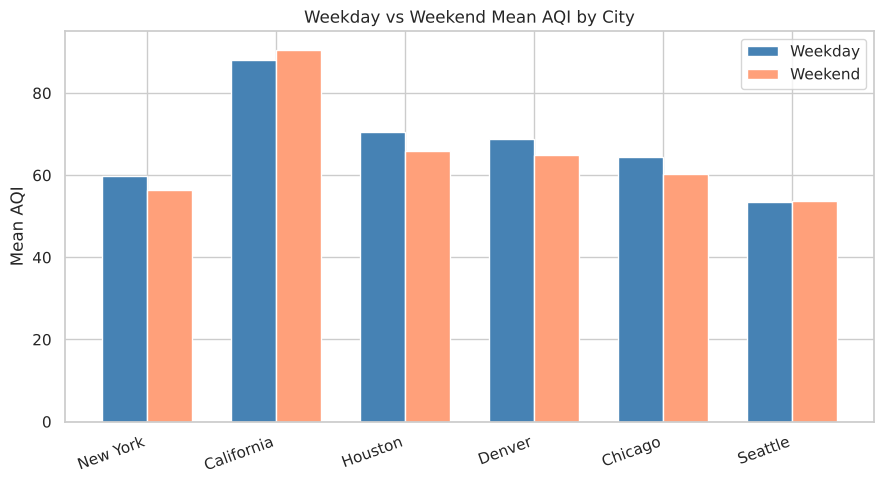

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(CITY_ORDER))
width = 0.35
ax.bar(x - width/2, dow_summary["weekday_mean_aqi"], width, label="Weekday", color="steelblue")
ax.bar(x + width/2, dow_summary["weekend_mean_aqi"], width, label="Weekend", color="lightsalmon")
ax.set_xticks(x)
ax.set_xticklabels(CITY_ORDER, rotation=20, ha="right")
ax.set_ylabel("Mean AQI")
ax.set_title("Weekday vs Weekend Mean AQI by City")
ax.legend()
plt.tight_layout()
plt.show()


## 10. Resolving the Open Questions From Section 4

Two things flagged while reviewing Section 4's charts, checked here with
code instead of left as a caveat in prose.

In [19]:
# (a) Is NY/Chicago's PM2.5 seasonal peak a real recurring pattern, or is
# it being pulled up by the single June 2023 wildfire smoke event? Testing
# the ACTUAL computed peak month (idxmax) with and without 2023, not a
# fixed assumed month — if the peak month itself shifts once 2023 is
# excluded, that's strong evidence it was an artifact, not a pattern.
for city in ["New York", "Chicago"]:
    city_pm25 = pollutants[(pollutants["city"] == city) & (pollutants["pollutant"] == "pm25")].copy()
    city_pm25["month"] = city_pm25["date"].dt.month
    city_pm25["year"] = city_pm25["date"].dt.year

    with_2023 = city_pm25.groupby("month")["value"].mean()
    without_2023 = city_pm25[city_pm25["year"] != 2023].groupby("month")["value"].mean()

    peak_with = with_2023.idxmax()
    peak_without = without_2023.idxmax()

    print(f"{city} — PM2.5 peak month: {peak_with} (all years, matches Section 7's offset table) vs {peak_without} (excluding 2023)")
    if peak_with != peak_without:
        print(f"  -> The peak month CHANGES when 2023 is excluded — the seasonal peak looks like an artifact of the 2023 event, not a stable recurring pattern.")
    else:
        print(f"  -> The peak month is unchanged even without 2023 — likely a real seasonal pattern, not just the 2023 event.")

    val_with = with_2023.loc[peak_with]
    val_without_at_same_month = without_2023.loc[peak_with]
    pct_drop = (val_with - val_without_at_same_month) / val_with * 100
    print(f"  Mean PM2.5 at month {peak_with}: {val_with:.1f} (all years) vs {val_without_at_same_month:.1f} (excl. 2023) -> {pct_drop:.0f}% of that month's average comes from 2023 alone")
    print()


New York — PM2.5 peak month: 7 (all years, matches Section 7's offset table) vs 7 (excluding 2023)
  -> The peak month is unchanged even without 2023 — likely a real seasonal pattern, not just the 2023 event.
  Mean PM2.5 at month 7: 10.1 (all years) vs 9.6 (excl. 2023) -> 5% of that month's average comes from 2023 alone

Chicago — PM2.5 peak month: 7 (all years, matches Section 7's offset table) vs 7 (excluding 2023)
  -> The peak month is unchanged even without 2023 — likely a real seasonal pattern, not just the 2023 event.
  Mean PM2.5 at month 7: 12.7 (all years) vs 12.6 (excl. 2023) -> 0% of that month's average comes from 2023 alone



In [20]:
# (b) Houston's ozone seasonal curve dipped in July between two peaks —
# check whether July simply has fewer observations than surrounding
# months, which could produce this shape without it being a real pattern.
houston_o3 = pollutants[(pollutants["city"] == "Houston") & (pollutants["pollutant"] == "o3")].copy()
houston_o3["month"] = houston_o3["date"].dt.month
obs_by_month = houston_o3.groupby("month").size()
print("Houston O3 — observation count by month:")
print(obs_by_month)
print()
if obs_by_month.loc[7] < obs_by_month.mean() * 0.7:
    print("July has a notably low sample size relative to other months — the dip may be a sampling artifact, not a real atmospheric pattern.")
else:
    print("July's sample size is in line with other months — the dip is not explained by a data gap, likely a genuine feature worth investigating further.")


Houston O3 — observation count by month:
month
1     4301
2     3922
3     4340
4     4203
5     4307
6     4167
7     4116
8     3650
9     3594
10    3749
11    3636
12    3606
dtype: int64

July's sample size is in line with other months — the dip is not explained by a data gap, likely a genuine feature worth investigating further.


## 11. Health Economic Impact Estimate

This section translates PM2.5 exceedance exposure into an order-of-magnitude estimate
of health economic impact, using publicly available federal valuation parameters.
Population-weighted exposure data used in this section (person-days of exceedance by city and county) is computed in Section 5.2 using Census ACS 2022 population data. Exceedance days are counted from daily station-level PM2.5 readings (a county counts once per day if any of its monitors exceeds 35 µg/m³).

**Methodology:**
- PM2.5 concentration-response function: a **10 µg/m³** increase in long-term mean
  PM2.5 exposure is associated with approximately a **6% increase** in all-cause
  mortality risk (Pope et al. 2002, ACS CPS-II cohort). Applied here as
  **0.6% per 1 µg/m³** (i.e. dividing the published coefficient by 10). Note: this CR function was derived from chronic exposure studies,
  not acute exposure events. Its application here to exceedance days only is
  a simplification — it likely overestimates risk for short acute episodes and
  underestimates it for cities with sustained elevated background levels. This
  is one reason the results are labeled "screening-level" and not suitable for
  regulatory analysis.
  
  <br>
  
- Value per Statistical Life (VSL): **$13.1 million** (2023 USD), from the U.S.
  Department of Health and Human Services standard regulatory analysis values
  (HHS, January 2024). Note: EPA suspended monetization of PM2.5 health benefits
  in 2026 pending methodology review; HHS VSL is used here as an alternative
  federal reference value.
  
  <br>
  
- Population-weighted excess exposure is estimated from the person-days of
  exceedance computed in Section 5.2, converted to annual excess µg/m³·person
  exposure above the 35 µg/m³ threshold.
  
  <br>

**Important caveats:**
This is a screening-level estimate, not a regulatory impact analysis. It uses
a simplified linear concentration-response function and a single VSL point
estimate. It is intended to illustrate the order of magnitude of health costs
associated with observed PM2.5 exceedances, not to produce precise mortality
or cost figures. Uncertainty in both the epidemiological parameters and the
VSL is substantial.

In [21]:
# ── Health Economic Impact Estimate ───────────────────────────────────────────
# DEPENDENCIES: pop_df (county population, Section 5.2) and pollutants (Section 1).
# VSL: HHS central estimate, 2023 USD (HHS Standard RIA Values, January 2024)
VSL_USD = 13_100_000

# Concentration-response: 6% increase in all-cause mortality per 10 µg/m³
# increase in long-term mean PM2.5 (Pope et al. 2002, ACS CPS-II cohort).
# Applied here as 0.6% per 1 µg/m³ (i.e. 0.006). Note: this is a chronic
# exposure coefficient applied to acute exceedance days — a known simplification
# documented as a limitation in the Section 11 markdown.
# Baseline annual mortality rate in the US: ~833 per 100,000 (CDC, 2022)
BASELINE_MORTALITY_RATE = 833 / 100_000

pm25_raw2 = pollutants[pollutants["pollutant"] == "pm25"].copy()
pm25_raw2["year"] = pm25_raw2["date"].dt.year

exceed_conc = (
    pm25_raw2[pm25_raw2["value"] > 35]
    .groupby(["city", "county", "year"])
    .agg(
        mean_excess_conc=("value", "mean"),
        n_days=("date", "nunique")
    )
    .reset_index()
)
exceed_conc["excess_above_threshold"] = exceed_conc["mean_excess_conc"] - 35

exceed_conc = exceed_conc.merge(
    pop_df[["city", "county", "population"]],
    on=["city", "county"], how="left"
)

exceed_conc["fraction_of_year"] = exceed_conc["n_days"] / 365
exceed_conc["attributable_deaths"] = (
    exceed_conc["population"]
    * BASELINE_MORTALITY_RATE
    * 0.006  # 6% per 10 µg/m³ → 0.6% per 1 µg/m³ (Pope et al. 2002)
    * exceed_conc["excess_above_threshold"]
    * exceed_conc["fraction_of_year"]
)
exceed_conc["economic_value_usd"] = exceed_conc["attributable_deaths"] * VSL_USD

impact_summary = (
    exceed_conc.groupby(["city", "year"])
    .agg(
        attributable_deaths=("attributable_deaths", "sum"),
        economic_value_usd=("economic_value_usd", "sum"),
    )
    .reset_index()
)
impact_summary["economic_value_bn"] = impact_summary["economic_value_usd"] / 1e9

print("Estimated health economic impact of PM2.5 exceedances (screening level)")
print("VSL = $13.1M (HHS 2024) | CR = 6% per 10 µg/m³ (0.6%/µg/m³) | Threshold = 35 µg/m³ (EPA 24-hour NAAQS)\n")

# ── Attributable deaths — styled table ────────────────────────────────────────
# Totals are summed from UNROUNDED values and rounded once, only for display,
# so the Total row always agrees with the summary table below.
pivot_deaths = impact_summary.pivot(
    index="year", columns="city", values="attributable_deaths"
).fillna(0).reindex(columns=CITY_ORDER)
pivot_deaths.loc["Total"] = pivot_deaths.sum()
pivot_deaths.columns.name = "City"
pivot_deaths.index.name = "Year"
display(pivot_deaths.style
    .format("{:.0f}")
    .background_gradient(cmap="YlOrRd", axis=None)
    .set_caption("Estimated attributable deaths per year (screening level)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)

# ── Economic value — styled table ─────────────────────────────────────────────
# Use economic_value_usd (not pre-rounded economic_value_bn) to avoid
# cumulative rounding errors that cause the Total row to differ from
# the summary table by $0.1B
pivot_econ_raw = impact_summary.pivot(
    index="year", columns="city", values="economic_value_usd"
).fillna(0).reindex(columns=CITY_ORDER) / 1e9
pivot_econ = pivot_econ_raw.copy()
pivot_econ.loc["Total"] = pivot_econ_raw.sum()  # sum unrounded; rounded once, in the display format
pivot_econ.columns.name = "City"
pivot_econ.index.name = "Year"
display(pivot_econ.style
    .format("${:.1f}B")
    .background_gradient(cmap="YlOrRd", axis=None)
    .set_caption("Estimated economic value of health impact (USD billion, screening level)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)

total_deaths = impact_summary["attributable_deaths"].sum()
total_value = impact_summary["economic_value_usd"].sum() / 1e9
print(f"\nTOTAL (all cities, 2020–2026, screening level):")
print(f"  Attributable deaths: {total_deaths:,.0f}")
print(f"  Economic value: ${total_value:.1f} billion")
print()
print("Note: These are order-of-magnitude estimates. Do not cite as precise figures.")
print("Actual health impacts depend on population age structure, baseline health,")
print("and local epidemiological parameters not captured in this simplified model.")
print(f"\n⚠ 2026 values are partial-year only (pollutant data through {pm25_raw2['date'].max():%d %b %Y}).")
print("  Do not compare 2026 figures directly to full-year estimates.\n")

# ── Per-capita economic impact — styled table ─────────────────────────────────
cbsa_pop = pop_df.groupby("city")["population"].sum().reset_index()
cbsa_pop.columns = ["city", "cbsa_population"]
impact_percapita = impact_summary.merge(cbsa_pop, on="city", how="left")
impact_percapita["econ_value_per_capita"] = (
    impact_percapita["economic_value_usd"] / impact_percapita["cbsa_population"]
)
pivot_pc = impact_percapita.pivot(
    index="year", columns="city", values="econ_value_per_capita"
).fillna(0).round(0).astype(int).reindex(columns=CITY_ORDER)
pivot_pc.columns.name = "City"
pivot_pc.index.name = "Year"
display(pivot_pc.style
    .format("${:,}")
    .background_gradient(cmap="YlOrRd", axis=None)
    .set_caption("Estimated health economic impact per capita (USD, screening level)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)

# ── Total by city across all years ────────────────────────────────────────────

total_by_city = (
    impact_summary.groupby("city")
    .agg(total_deaths=("attributable_deaths", "sum"),
         total_econ_usd=("economic_value_usd", "sum"))
    .reindex(CITY_ORDER)
    .reset_index()
    .merge(cbsa_pop, on="city", how="left")
)
# Everything is computed from unrounded values; rounding happens only in the display format
total_by_city["total_econ_bn"] = total_by_city["total_econ_usd"] / 1e9
total_by_city["total_econ_per_capita"] = (
    total_by_city["total_econ_usd"] / total_by_city["cbsa_population"]
)
total_by_city = total_by_city.set_index("city")
total_by_city.index.name = "City"

display(total_by_city[["total_deaths", "total_econ_bn", "total_econ_per_capita"]].rename(columns={
    "total_deaths": "Attributable deaths",
    "total_econ_bn": "Economic cost (USD bn)",
    "total_econ_per_capita": "Cost per capita (USD)"
}).style.format({
    "Attributable deaths": "{:,.0f}",
    "Economic cost (USD bn)": "${:.1f}B",
    "Cost per capita (USD)": "${:,.0f}"
})
.background_gradient(subset=["Cost per capita (USD)"], cmap="YlOrRd")
.set_caption("Total health economic impact, 2020–2026 (screening level) · 2026 is a partial year")
.set_table_styles([{"selector": "caption",
                    "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)

Estimated health economic impact of PM2.5 exceedances (screening level)
VSL = $13.1M (HHS 2024) | CR = 6% per 10 µg/m³ (0.6%/µg/m³) | Threshold = 35 µg/m³ (EPA 24-hour NAAQS)



City,New York,California,Houston,Denver,Chicago,Seattle
Year,,,,,,
2020,2,852,26,9,5,452
2021,43,331,8,14,16,8
2022,0,85,2,0,3,245
2023,553,130,6,22,326,39
2024,3,276,26,0,4,3
2025,1,342,2,0,147,2
2026,2,64,26,0,362,0
Total,603,2081,96,45,863,750


City,New York,California,Houston,Denver,Chicago,Seattle
Year,,,,,,
2020,$0.0B,$11.2B,$0.3B,$0.1B,$0.1B,$5.9B
2021,$0.6B,$4.3B,$0.1B,$0.2B,$0.2B,$0.1B
2022,$0.0B,$1.1B,$0.0B,$0.0B,$0.0B,$3.2B
2023,$7.2B,$1.7B,$0.1B,$0.3B,$4.3B,$0.5B
2024,$0.0B,$3.6B,$0.3B,$0.0B,$0.1B,$0.0B
2025,$0.0B,$4.5B,$0.0B,$0.0B,$1.9B,$0.0B
2026,$0.0B,$0.8B,$0.3B,$0.0B,$4.7B,$0.0B
Total,$7.9B,$27.3B,$1.3B,$0.6B,$11.3B,$9.8B



TOTAL (all cities, 2020–2026, screening level):
  Attributable deaths: 4,438
  Economic value: $58.1 billion

Note: These are order-of-magnitude estimates. Do not cite as precise figures.
Actual health impacts depend on population age structure, baseline health,
and local epidemiological parameters not captured in this simplified model.

⚠ 2026 values are partial-year only (pollutant data through 27 Jul 2026).
  Do not compare 2026 figures directly to full-year estimates.



City,New York,California,Houston,Denver,Chicago,Seattle
Year,,,,,,
2020,$1,$851,$55,$42,$8,"$1,480"
2021,$28,$330,$17,$62,$25,$27
2022,$0,$85,$4,$0,$4,$803
2023,$361,$130,$12,$100,$489,$127
2024,$2,$276,$56,$0,$6,$9
2025,$1,$342,$5,$0,$220,$6
2026,$1,$64,$56,$0,$543,$1


,Attributable deaths,Economic cost (USD bn),Cost per capita (USD)
City,,,
New York,603,$7.9B,$394
California,"2,081",$27.3B,"$2,079"
Houston,96,$1.3B,$206
Denver,45,$0.6B,$204
Chicago,863,$11.3B,"$1,294"
Seattle,750,$9.8B,"$2,455"


### 11.1 Quebec Smoke Event: Event Days Only

The annual figures above count every PM2.5 exceedance day of a year. For the June 2023
Quebec smoke event that over-attributes cost to the event, because the same year also contains
exceedance days outside it. This cell recomputes person-days, attributable deaths and cost
using **only the documented event days** (the same windows as Section 6: New York 6–8 June 2023,
Chicago 27–28 June 2023), with exactly the same method as Section 11.

The windows are the peak days, so the result is a conservative (lower) reading of the event;
the full-year 2023 figures are shown next to it for reference.


In [22]:
# ── Quebec smoke event: person-days and cost on the documented event days only ─
# Same method as the annual calculation above (same VSL, CR, baseline mortality,
# threshold and population), restricted to the event windows from Section 6.
def event_impact(city, start, end):
    window = pm25_raw2[
        (pm25_raw2["city"] == city)
        & (pm25_raw2["date"] >= start) & (pm25_raw2["date"] <= end)
        & (pm25_raw2["value"] > 35)
    ]
    ev = (
        window.groupby("county")
        .agg(mean_conc=("value", "mean"), n_days=("date", "nunique"))
        .reset_index()
    )
    ev["city"] = city
    ev = ev.merge(pop_df[["city", "county", "population"]], on=["city", "county"], how="left")
    ev["person_days"] = ev["n_days"] * ev["population"]
    ev["deaths"] = (
        ev["population"] * BASELINE_MORTALITY_RATE * 0.006
        * (ev["mean_conc"] - 35) * (ev["n_days"] / 365)
    )
    ev["cost_usd"] = ev["deaths"] * VSL_USD
    return ev

rows = []
for (city, year, month), (start, end) in EVENT_DAY_RANGES.items():
    ev = event_impact(city, start, end)
    full = impact_summary[(impact_summary["city"] == city) & (impact_summary["year"] == year)].iloc[0]
    full_pd = person_days_summary[
        (person_days_summary["city"] == city) & (person_days_summary["year"] == year)
    ]["person_days"].iloc[0]
    rows.append({
        "City": city,
        "Event days": f"{start} to {end}",
        "County-days > 35": int(ev["n_days"].sum()),
        "Person-days, event (M)": ev["person_days"].sum() / 1e6,
        "Deaths, event": ev["deaths"].sum(),
        "Cost, event (USD bn)": ev["cost_usd"].sum() / 1e9,
        "Person-days, all 2023 (M)": full_pd / 1e6,
        "Deaths, all 2023": full["attributable_deaths"],
        "Cost, all 2023 (USD bn)": full["economic_value_usd"] / 1e9,
    })

quebec = pd.DataFrame(rows).set_index("City")
display(quebec.style
    .format({
        "County-days > 35": "{:,}",
        "Person-days, event (M)": "{:.1f}M",
        "Deaths, event": "{:,.0f}",
        "Cost, event (USD bn)": "${:.1f}B",
        "Person-days, all 2023 (M)": "{:.1f}M",
        "Deaths, all 2023": "{:,.0f}",
        "Cost, all 2023 (USD bn)": "${:.1f}B",
    })
    .set_caption("June 2023 Quebec smoke: event days only vs all PM2.5 exceedance days of 2023 (screening level)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)
print("Event-day windows are the peak days (conservative). All-2023 totals also include")
print("exceedance days outside the event windows, which are not separated here.")


,Event days,County-days > 35,"Person-days, event (M)","Deaths, event","Cost, event (USD bn)","Person-days, all 2023 (M)","Deaths, all 2023","Cost, all 2023 (USD bn)"
City,,,,,,,,
New York,2023-06-06 to 2023-06-08,52,53.5M,418,$5.5B,94.0M,553,$7.2B
Chicago,2023-06-27 to 2023-06-28,15,17.0M,200,$2.6B,59.8M,326,$4.3B


Event-day windows are the peak days (conservative). All-2023 totals also include
exceedance days outside the event windows, which are not separated here.


### Risk Implications for Business and Investment Decisions

These screening-level estimates translate into concrete operational risk contexts:

**Workforce exposure:** For outdoor-worker protection planning, employers in Los Angeles face an estimated 15 days per year on average (2020–2026, with 2026 a partial year), with a peak of 38 days in 2020 (wildfire year), where PM2.5 levels exceed the EPA 24-hour threshold of 35 µg/m³ at any station. For Seattle, this number averages around 8 days/year but spikes in wildfire years (2020: 14 days, 2022: 26 days), making year-to-year planning unreliable. The per-year counts for every city are in the table below.

**Insurance and liability:** The June 2023 Quebec smoke event is a cross-border, multi-city event with no local emission source. Counting only the documented event days (New York 6–8 June, Chicago 27–28 June, the same windows used in Section 6), the estimate is **USD 5.5B in health costs in New York (418 attributable deaths) and USD 2.6B in Chicago (200 deaths)**. Counting every PM2.5 exceedance day of 2023 gives the larger figures **USD 7.2B and USD 4.3B**, but that annual total also includes exceedance days outside the event windows (some of them probably smoke-related, which this analysis does not separate). The event-day figures are therefore the more conservative reading. This type of transported risk is not captured by traditional local air quality monitoring and represents a growing tail risk for property and casualty insurers operating in these markets.

**Portfolio screening:** California's cumulative health cost of **USD 27.3B (2020–2026)** — roughly USD 3.9B per calendar year, with 2026 a partial year — provides a consistent order-of-magnitude benchmark for climate risk physical exposure screening.

*All figures are screening-level estimates using Pope et al. 2002 (6%/10µg/m³, all-cause mortality) and VSL USD 13.1M (HHS 2024). See methodology note above for assumptions and limitations.*


In [23]:
# ── Days per year exceeding the PM2.5 35 µg/m³ threshold, all cities ──────────
# This backs the figures cited in the Risk Implications note above
# (California and Seattle). A day counts if ANY station in the metro area exceeded 35.
days_exceed = (
    pm25_raw2[pm25_raw2["value"] > 35]
    .groupby(["year", "city"])["date"].nunique()
    .unstack("city")
    .reindex(index=range(2020, 2027), columns=CITY_ORDER)
    .fillna(0)
    .astype(int)
)
days_exceed.index.name = "Year"
days_exceed.columns.name = "City"

display(days_exceed.style
    .format("{:.0f}")
    .background_gradient(cmap="YlOrRd", axis=None)
    .set_caption("Days per year with station-level PM2.5 > 35 µg/m³ (2026 is a partial year)")
    .set_table_styles([{"selector": "caption",
                        "props": [("font-size", "13px"), ("font-weight", "bold")]}])
)
print(f"California annual mean: {days_exceed['California'].mean():.1f} days/year (peak {days_exceed['California'].max()} in {days_exceed['California'].idxmax()})")
print(f"Seattle annual mean:    {days_exceed['Seattle'].mean():.1f} days/year (2020: {days_exceed.loc[2020, 'Seattle']}, 2022: {days_exceed.loc[2022, 'Seattle']})")


City,New York,California,Houston,Denver,Chicago,Seattle
Year,,,,,,
2020,1,38,3,11,3,14
2021,2,18,1,10,7,4
2022,0,8,3,0,3,26
2023,10,4,2,4,12,5
2024,2,15,6,1,1,1
2025,5,18,2,0,15,2
2026,2,5,2,0,5,2


California annual mean: 15.1 days/year (peak 38 in 2020)
Seattle annual mean:    7.7 days/year (2020: 14, 2022: 26)


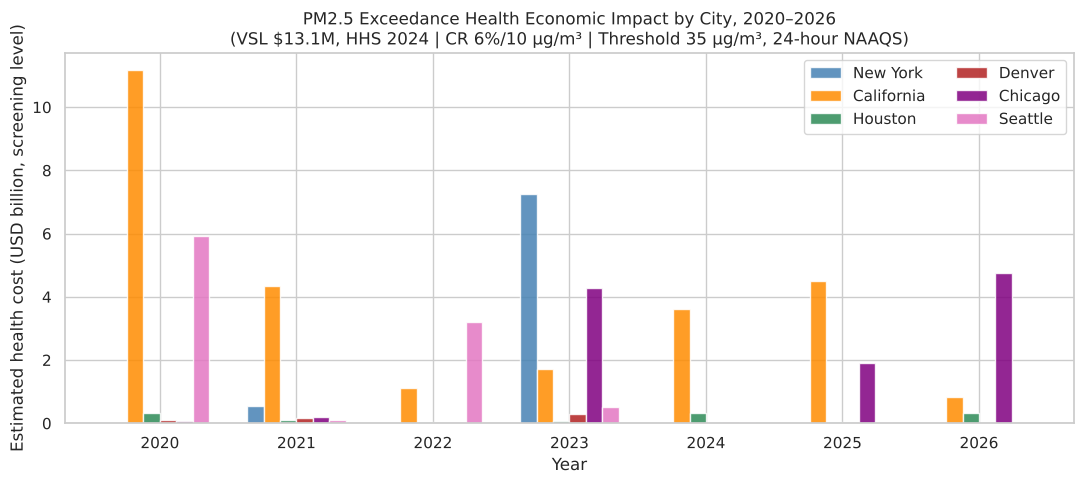

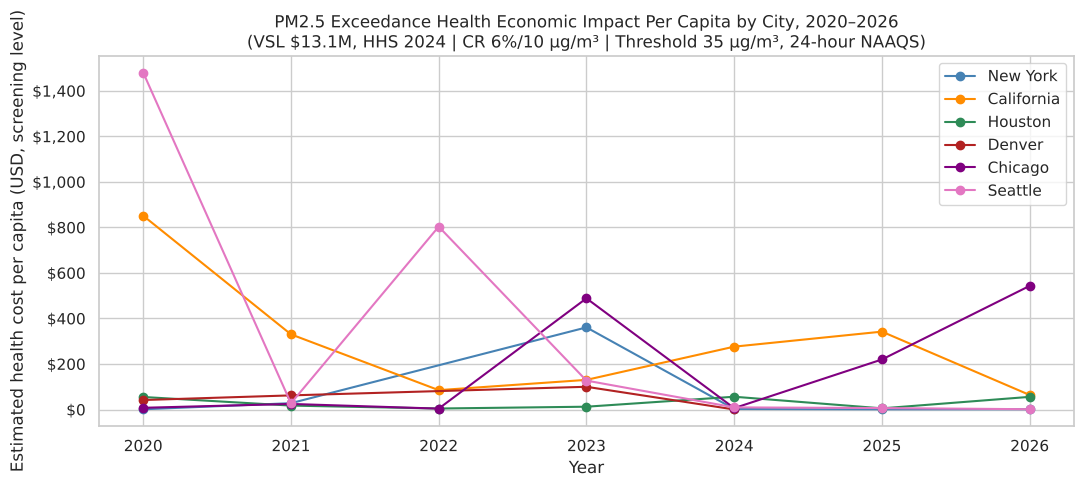

In [24]:
# ── Bar chart: total economic impact by city and year ─────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
for city in CITY_ORDER:
    city_data = impact_summary[impact_summary["city"] == city]
    if len(city_data) and city_data["economic_value_bn"].sum() > 0:
        ax.bar(
            city_data["year"] + list(CITY_ORDER).index(city) * 0.12 - 0.3,
            city_data["economic_value_bn"],
            width=0.12,
            label=city,
            color=CITY_COLOR[city],
            alpha=0.85
        )
ax.set_ylabel("Estimated health cost (USD billion, screening level)")
ax.set_title("PM2.5 Exceedance Health Economic Impact by City, 2020–2026\n"
             "(VSL $13.1M, HHS 2024 | CR 6%/10 µg/m³ | Threshold 35 µg/m³, 24-hour NAAQS)")
ax.set_xlabel("Year")
ax.legend(ncol=2)
ax.set_xticks(list(range(2020, 2027)))
plt.tight_layout()
plt.show()


fig2, ax2 = plt.subplots(figsize=(11, 5))
for city in CITY_ORDER:
    city_data = impact_percapita[impact_percapita["city"] == city]
    if len(city_data) and city_data["econ_value_per_capita"].sum() > 0:
        ax2.plot(city_data["year"], city_data["econ_value_per_capita"],
                 marker="o", label=city, color=CITY_COLOR[city])
ax2.set_ylabel("Estimated health cost per capita (USD, screening level)")
ax2.set_title("PM2.5 Exceedance Health Economic Impact Per Capita by City, 2020–2026\n"
              "(VSL $13.1M, HHS 2024 | CR 6%/10 µg/m³ | Threshold 35 µg/m³, 24-hour NAAQS)")
ax2.set_xlabel("Year")
ax2.set_xticks(list(range(2020, 2027)))
ax2.legend()
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.show()


## 12. Conclusions

*Every figure below is traceable to a printed output in Sections 3–11
(2020–2026 dataset; the year-over-year trend test uses the complete years
2020–2025 only). Where a claim goes beyond what the outputs
strictly show — an external attribution of cause, or an interpretation —
it is marked as such rather than stated as a finding.*

*Legend: 📊 = directly traceable to a cell output · 💡 = interpretation beyond what the data strictly shows*

📊 **1. California is not just the worst city in this comparison, it is in a
   different tier entirely...** Mean AQI 88.8 (median 75) vs 53.5–69.1 for
   the other five, and 10.7% of days above the "Unhealthy" threshold —
   roughly 4–13x the rate of every other city (Houston 2.6%, the next
   highest). This gap, not any single event, is the headline finding of
   the project (Section 3).

📊💡 **2. "Worst day" and "worst pattern" are two different things, and cities
   split between them...** California's single worst day (Oct 11 2021,
   AQI 281) was defined by PM10 rather than PM2.5 or Ozone — most likely
   a dust event rather than wildfire smoke, though the data gives only
   the defining pollutant, not the cause. It is distinct from the rest
   of its top-10, where Ozone defines 6 of the 8 2020 entries and PM2.5
   the other 2 (8 of its 9 total entries fall in 2020, the remaining one
   in 2024). Seattle shows the same split at a smaller scale: the lowest
   mean AQI of all six cities (53.5) but the single highest AQI recorded
   anywhere in this dataset (362, "Hazardous", Oct 19 2022) — a city
   clean most of the year, punctuated by extreme, short-lived smoke
   events (Sept 2020 and Oct 2022, both 100% PM2.5-driven in the top-10,
   no Ozone or PM10 day appears at all) (Section 4).

📊💡 **3. The June 2023 Quebec wildfire smoke event reached both New York and
   Chicago...**, confirmed independently in both cities' top-10 tables (NY:
   June 6–8, AQI up to 278; Chicago: June 27–28, AQI up to 246). These are
   the peak days used as the event windows throughout this notebook; the
   elevated PM2.5 in Chicago lasted longer (roughly 26–30 June), so the
   event-day estimates in Section 11 are conservative. Surface
   wind during those exact event days does not point toward Quebec — NY's
   247° is WSW (west-southwest) and Chicago's 147° is SSE
   (south-southeast), neither close to the north/northeast a direct
   surface transport path from Quebec would suggest. This is not a data
   error: it is consistent with how this specific event is documented
   elsewhere — the smoke traveled at altitude, carried by a different
   wind pattern than at ground level, and settled locally. Ground-level
   EPA wind stations do not capture that upper-air transport, so this
   should be stated explicitly rather than implied to be confirmed by
   surface wind (Section 6).

📊💡 **4. PM2.5–PM10 correlation ranges from weak to strong across cities, not
   uniformly "moderate..."** New York: r=0.85 (strong) — but read with
   caution, since New York has by far the fewest paired PM2.5/PM10 days
   of the six cities (512 city-days, vs 2,400 for Chicago and California;
   its PM10 series is also the sparsest in the dataset, 1,890 county-level
   daily readings vs 11,571 for Chicago), so this coefficient rests on much
   less data than the others and any causal reading of it (shared
   traffic/heating sources) is an interpretation, not a result.
   Seattle r=0.72 (1,231 days), Chicago r=0.70 (moderate-strong).
   California r=0.63, Denver r=0.52 (moderate). Houston r=0.48 (the
   weakest of the six) — consistent with a more varied industrial/
   petrochemical source mix, where PM2.5 and PM10 are less likely to be
   driven by the same events (Section 7).

📊💡 **5. Houston has a recurring New Year's Day PM2.5 spike...**, appearing in
   the top-10 worst-AQI-days list in two separate years (Jan 1 2020,
   AQI 190; Jan 1 2024, AQI 184) — almost certainly fireworks, not the
   city's usual industrial/ozone mechanism. Labeled explicitly rather
   than left as an unexplained anomaly (Section 4).

📊💡 **6. Denver's ozone seasonality is the cleanest single-mechanism pattern
   of the six cities..** — one smooth summer peak, no secondary structure,
   consistent with straightforward summer photochemistry. Its original
   "Valley thermal inversion" label (assigned in `regions.csv` before
   this data was collected) was a mismatch: classic thermal-inversion
   smog in Denver is a winter phenomenon, but this city's heatmap and
   top-10 table show summer as consistently the worst season and winter
   as the cleanest. The label in `regions.csv` (and therefore this
   city's chart title in Section 4) has already been updated to "Summer
   photochemical ozone" to reflect this — this point is recorded here as
   a worked example of catching a mechanism assumption that didn't match
   the data, not as an outstanding fix. Two entries fall outside the
   June–September window: March 8 2022 (AQI 190, Ozone) and May 19 2023
   (AQI 179, PM2.5) — both are treated as isolated events, not folded
   into the seasonal narrative (Section 4).

📊 **7. Pollution concentration within a CBSA varies by how many counties
   actually report data, which limits what can be said for some cities...**
   New York (22 counties) is genuinely spread out — the top county
   (Union, 8.6 µg/m³ PM2.5) is close to several others (Essex 8.5,
   Bergen 8.0, Kings 7.9), not a single dominant hotspot. Chicago
   (8 counties) and Denver (8 counties) show a similar pattern, with
   DuPage/Cook (9.5/9.3) and Denver/Adams (7.3/7.3) essentially tied
   at the top. Houston (4 counties) follows the same pattern rather than
   being the concentrated exception: Harris (10.2) and Montgomery (10.0)
   are effectively tied at the top, with Galveston and Brazoria
   (7.9/7.8) trailing — so the petrochemical mechanism does not show up
   as a single dominant hotspot county in this data, contrary to what
   might be expected. California and Seattle can't meaningfully answer
   this question — only 2 and 3 counties report respectively, too few
   to distinguish "concentrated" from "evenly spread" with any confidence
   (Section 5).

📊💡 **8. Population-weighted exposure reveals a different ranking than raw
   exceedance counts...** California dominates in absolute person-days
   (396M in 2020), but Seattle's 2020 event (47.7M person-days despite
   having only 4M residents) demonstrates that low-population cities can
   generate outsized per-capita exposure during extreme events. The
   Quebec smoke event days alone (New York 6–8 June, Chicago 27–28 June
   2023) produced about 53.5M person-days in New York and 17.0M in Chicago
   (Section 11); counting every exceedance day of 2023 the totals are 94.0M
   and 59.8M. Even on three days, New York's event exposure is comparable
   to Seattle's entire 2020. This metric is more relevant for insurance,
   public health planning, and corporate risk disclosure than raw AQI
   counts (Section 5.2, Census ACS 2022 population data).

📊 **9. Year-over-year trend is not uniform, and no city shows a statistically significant trend at the 95% level over the complete years 2020–2025.** Houston is the only city close to significance, with a marginal upward trend (Mann-Kendall τ=+0.733, p=0.056), consistent with its AQI rising from 62.0 in 2020 to 74.9 in 2024 (71.4 in 2025). California is directionally downward but not significant (τ=−0.467, p=0.272), as is Seattle (τ=−0.467, p=0.272); Denver (τ=−0.333, p=0.469), New York (τ=+0.200, p=0.719) and Chicago (τ=−0.067, p=1.000) show no consistent direction. The absence of significance is expected with 6 data points and reflects limited test power, not the absence of real trends (Section 8.2). 2026 is excluded from the test because it is a partial year that covers only some seasons, with a different cut-off per city (Section 8).


📊 **10. The weekday-over-weekend AQI gap is real in four of the six cities
    — but does not cleanly isolate a traffic signal...** The gaps: Houston
    +4.50, Chicago +4.27, Denver +3.84, New York +3.38, Seattle −0.23,
    California −2.43. Bootstrap 95% confidence intervals (Section 9)
    separate these into two groups: the four positive gaps are all
    clearly above zero (New York [+1.63, +5.23], Houston [+2.04, +6.84],
    Denver [+1.64, +5.91], Chicago [+2.45, +6.08]), while California
    [−5.96, +0.86] and Seattle [−2.27, +1.76] both cross zero — meaning
    no detectable gap either way, not a reversed one. The four positive
    intervals overlap heavily, so ranking them against each other is not
    supported. The honest read: this test does not confirm the mechanism
    labels. The two cities with no detectable gap (California, Seattle)
    are also the two whose worst days are dominated by wildfire smoke,
    which has no weekly cycle — a plausible explanation for the absence,
    though with only six cities this is a suggestive pattern, not a
    demonstrated one (Section 9).

💡 **11. A screening-level health economic analysis estimates USD 58.1 billion
    in cumulative health costs (4,438 attributable deaths) across the six
    metro areas over 2020–2026...** (VSL 13.1M USD, HHS 2024;
    concentration-response function 6%/10µg/m³, Pope et al. 2002; threshold
    35 µg/m³, EPA 24-hour NAAQS). California accounts for the largest
    single-year figure (11.2B USD in 2020), followed by Seattle 2020 (5.9B
    USD) — the latter driven by extreme per-capita exposure during wildfire
    smoke events rather than chronic pollution. For the June 2023 Quebec
    smoke event, counting only the event days (New York 6–8 June, Chicago
    27–28 June), the estimate is 5.5B USD in New York (418 deaths) and 2.6B
    USD in Chicago (200 deaths); counting every exceedance day of 2023 it
    is 7.2B USD and 4.3B USD, a total that also includes days outside the
    event windows. On three days alone, New York's event cost is comparable
    to Seattle's entire 2020 (5.9B USD). Chicago's largest year is 2026
    (4.7B USD, a partial year), driven by the 16–20 July 2026 episode, which
    falls after the end of the AQI series and so does not appear in
    Sections 3–8. New York's total (7.9B USD, 2020–2026) reflects the
    22-county New York metro population (20.1M) used in this project. These
    figures are order-of-magnitude estimates only: they use a simplified
    linear CR function applied to acute exceedance days (a known
    limitation — the Pope 2002 coefficient was derived from chronic
    long-term exposure), a single VSL point estimate, and a uniform baseline
    mortality rate. They are not suitable for regulatory analysis but are
    appropriate for illustrating the scale of health costs associated with
    observed exceedances for risk communication and portfolio screening
    purposes. Note: 2026 values are partial-year and not directly
    comparable to full-year figures (Section 11).
